# COMP6010 Assignment — Part C (Option C2): Animal-Drawing Generation with Flow Matching

**Student:** Satria Pamungkas &nbsp;|&nbsp; **Student ID:** 21522611 &nbsp;|&nbsp; **Option:** C2

**Goal.** Train a small conditional flow-matching model from scratch that turns Gaussian noise into
simple animal drawings (Quick, Draw! `cat`, `dog`, `fish`), and visualise the transformation.

**Data.** Google Quick, Draw! `numpy_bitmap` files — 28×28 centred grayscale bitmaps.
Attribution: *Quick, Draw! Dataset*, Google Creative Lab, CC BY 4.0. 4,000 original drawings per
category, split 80/20 by original drawing before any augmentation.

**This notebook is fully self-contained.** It downloads the dataset itself, and it loads
`checkpoints/baseline/*.pt` if they already exist (so you can reproduce every figure without
retraining) or trains from scratch if they do not. Results are written to `results/partC/`.

**Contents.** 1 method and research questions · 2 data download and inspection · 3 model, training and
the three key code sections · 4 comparison 1 (training factor) · 5 comparison 2 (inference factor) ·
6 evaluation · 7 memorisation probe · 8 interpretation.

In [1]:
%pip install -r requirements_frozen.txt

Defaulting to user installation because normal site-packages is not writeable
  Using cached jupyter_events-0.9.0-py3-none-any.whl.metadata (5.7 kB)
  Using cached jupyter_lsp-2.2.2-py3-none-any.whl.metadata (1.8 kB)
  Using cached jupyter_client-8.6.0-py3-none-any.whl.metadata (8.3 kB)
  Using cached jupyter_core-5.7.1-py3-none-any.whl.metadata (3.4 kB)
  Using cached jupyter_server-2.12.5-py3-none-any.whl.metadata (8.4 kB)
  Using cached jupyter_server_terminals-0.5.2-py3-none-any.whl.metadata (5.6 kB)
  Using cached jupyterlab-4.0.12-py3-none-any.whl.metadata (15 kB)
  Using cached jupyterlab_server-2.25.2-py3-none-any.whl.metadata (5.9 kB)
  Using cached matplotlib-3.10.8-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (52 kB)
  Using cached matplotlib_inline-0.1.6-py3-none-any.whl.metadata (2.8 kB)
  Using cached nbconvert-7.14.2-py3-none-any.whl.metadata (7.7 kB)
  Using cached notebook-7.0.7-py3-none-any.whl.metadata (10 kB)
  Using cached notebook_shim-0.2.3

In [2]:
# ============================================================== setup and folders
import os, sys, json, time, math, platform, hashlib, urllib.request
from itertools import product

import numpy as np
import pandas as pd
import torch
from torch import nn, Tensor
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

# ---- where things live. Everything is relative to this notebook's folder, so the notebook works
# ---- whether it sits at the top level or inside a notebooks/ subfolder.
HERE = os.path.abspath(os.getcwd())

def pick_dir(*candidates):
    """Return the first candidate that ALREADY EXISTS; otherwise create the last one.

    Preferring an existing folder is what makes the notebook find checkpoints and data that are
    already on disk. Checking only whether the *parent* exists is not enough: run from a folder
    whose parent is something like /tmp, and "../checkpoints" would resolve outside the project,
    silently missing the real checkpoints and retraining from scratch.
    """
    for c in candidates:
        c = os.path.abspath(c)
        if os.path.isdir(c):
            return c
    chosen = os.path.abspath(candidates[0])      # candidates[0] is always beside the notebook
    os.makedirs(chosen, exist_ok=True)
    return chosen

# Prefer a folder that already exists (either beside the notebook or one level up, which is where
# they sit if this notebook lives in a notebooks/ subfolder). Otherwise create it beside the
# notebook -- never outside the project.
RES  = pick_dir(os.path.join(HERE, "results", "partC"),
                os.path.join(HERE, "..", "results", "partC"))
GRID = pick_dir(os.path.join(RES, "sample_grids"))
DATA = pick_dir(os.path.join(HERE, "data", "quickdraw"),
                os.path.join(HERE, "..", "data", "quickdraw"))
CKPT = pick_dir(os.path.join(HERE, "checkpoints"),
                os.path.join(HERE, "..", "checkpoints"))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Bitwise-reproducible sampling on GPU. Without this, cuDNN may pick different convolution
# algorithms on different runs, so two runs of the SAME seed differ by about 7e-4 -- visually
# irrelevant, but enough that "same seed, same picture" is only true to plotting accuracy.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cuda.matmul.allow_tf32 = False

plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 170, "font.size": 8, "axes.grid": False})
pd.set_option("display.width", 190, "display.precision", 4)

# ---- fixed experiment settings ----
CATEGORIES   = ["cat", "dog", "fish"]
N_PER_CAT    = 4000          # original drawings kept per category
TRAIN_FRAC   = 0.8
IMG          = 28
GLOBAL_SEED  = 20260910      # data subset, split and training seed
INK_MIN, INK_MAX = 0.05, 0.55   # disclosed filter, calibrated in section 2

# Predetermined generation seeds, fixed once and reused in EVERY comparison. 32 seeds x 3 classes
# = 96 outputs per configuration. The brief requires >= 16 total and >= 4 per class; I use more
# because at 24 outputs the margin of error (~0.09) is too coarse to separate configurations at all.
SEED_LIST = [101, 202, 303, 404, 505, 606, 707, 808,
             909, 1010, 1111, 1212, 1313, 1414, 1515, 1616,
             1717, 1818, 1919, 2020, 2121, 2222, 2323, 2424,
             2525, 2626, 2727, 2828, 2929, 3030, 3131, 3232]

print(f"device   : {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU      : {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)")
print(f"torch    : {torch.__version__} | numpy {np.__version__} | python {sys.version.split()[0]}")
print(f"platform : {platform.platform()}")
print(f"\nresults     -> {RES}")
print(f"data        -> {DATA}")
print(f"checkpoints -> {CKPT}")
print(f"\n{len(SEED_LIST)} generation seeds -> {len(SEED_LIST)*len(CATEGORIES)} outputs per configuration"
      f"; margin of error at that size is +/-{np.sqrt(0.25/(len(SEED_LIST)*3)):.3f} (worst case)")

device   : cpu
torch    : 2.3.0+cu121 | numpy 1.26.4 | python 3.10.12
platform : Linux-6.8.0-138-generic-x86_64-with-glibc2.35

results     -> /home/21522611/Documents/PHUIML-Assignment/results/partC
data        -> /home/21522611/Documents/PHUIML-Assignment/data/quickdraw
checkpoints -> /home/21522611/Documents/PHUIML-Assignment/checkpoints

32 generation seeds -> 96 outputs per configuration; margin of error at that size is +/-0.051 (worst case)


/usr/local/lib/python3.10/dist-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Method and research questions

### What I aim to generate, and from what data

A **class-conditional generative model** over 28×28 grayscale line drawings. Given a requested
category $y \in \{\texttt{cat}, \texttt{dog}, \texttt{fish}\}$ and a fresh Gaussian noise image, the
model must output a new drawing of that category that was not in the training set.

### The method: straight-line (conditional) flow matching

Take a noise image $x_0 \sim \mathcal{N}(0, I)$ and a real drawing $x_1 \sim p_{\text{data}}$, and
slide in a straight line from one to the other. At time $t$ you are at

$$x_t = (1-t)\,x_0 + t\,x_1, \qquad\text{moving at speed}\qquad u_t = \frac{dx_t}{dt} = x_1 - x_0, \qquad t \sim \mathcal{U}[0,1]$$

Because the path is straight the speed is the **same everywhere**, and it is just the difference
between the two ends. So I train a network $v_\theta(t, x_t, y)$ to predict it with ordinary squared
error:

$$\mathcal{L}_{\text{CFM}}(\theta) = \mathbb{E}_{t,\;x_0,\;(x_1,y)}\Big[\big\| v_\theta(t, x_t, y) - (x_1 - x_0) \big\|^2\Big]$$

Nothing is simulated during training — the correct answer is available directly. To generate, start
from fresh noise and follow the predicted speeds from $t=0$ to $t=1$:

$$\frac{dx}{dt} = v_\theta(t, x, y), \qquad x(0) = x_0 \sim \mathcal{N}(0,I) \;\longrightarrow\; x(1) \approx \text{a drawing of class } y$$

```
 TRAINING (correct answer known in advance -- no path is simulated)
   x0 ~ N(0,I) ─┐                                  target u = x1 - x0
                ├─► x_t = (1-t)x0 + t·x1 ──► v_θ(t, x_t, y) ──► squared error ──► ∇θ
   x1 ~ p_data ─┘        ▲                              ▲
   y = class label       │ t ~ U[0,1]                   │ y (class embedding)

 GENERATING (follow the speeds forward)
   x0 ~ N(0,I) ──► [ x ← x + Δt·v_θ(t,x,y) ] × n_steps ──► x(1) = drawing
                     t: 0 → 1                    (Euler; midpoint uses 2 calls/step)
```

One worry: the same halfway image $x_t$ could have come from many noise-and-drawing pairs, so which
speed is "correct"? Squared error always settles on the **average** answer, so the network learns
$\mathbb{E}[x_1 - x_0 \mid x_t, y]$ — and flow matching's key result is that following those average
speeds turns noise into the data distribution exactly. The network never guesses which pair it came
from; it learns the typical direction of travel, which is all generation needs.

### Link to the unit: known structure, unknown component, generation by sampling

The same three ingredients as Parts A and B:

| | Part A | Part B | Part C (here) |
|---|---|---|---|
| **known structure** | the graph and its CPTs | Bernoulli likelihood + Beta prior | the noise distribution $\mathcal{N}(0,I)$ and the straight-line path — both chosen by me, not learned |
| **unknown part learned from data** | nothing (CPTs given) | the single number $\theta$ | the speed field $v_\theta$ — millions of parameters, but like A and B it is an average |
| **generation / inference by sampling** | forward + rejection + likelihood weighting | posterior draws for $P(\theta>0.8)$ | follow the path from a fresh $x_0$ |

The link to A4 is exact. The straight line is a **known** way to corrupt a drawing into noise, but
knowing that forward direction does not give me the way back, because the average speed
$\mathbb{E}[x_1-x_0 \mid x_t]$ depends on what real drawings look like — which is what the network
learns from data. That is the same trap as forcing downstream evidence in a forward sampler and
expecting the posterior: a known forward process never hands you the reverse one for free.

### The two research questions

**Q1 (training factor) — Does training longer make drawings more recognisable, and does it cost
variety?** I compare checkpoints at epochs 5, 15 and 60 with data, seeds and sampler held fixed.
*Prediction, written before running:* a big jump from epoch 5 to 15, then flat; held-out loss keeps
falling; variety unchanged, because flow matching predicts an average rather than competing against a
discriminator. A second run on a quarter of the data tests whether the limit is data or training time.

**Q2 (inference factor) — How few steps can I get away with, and does midpoint beat Euler at equal
network calls?** I compare step counts $\{2, 5, 10, 25, 50, 100\}$ for Euler, and Euler against
midpoint at **matched number of function evaluations (NFE)**, not matched steps. *Prediction:* few
steps needed, levelling off by 10–25; at equal NFE midpoint gains little, because straight-trained
paths barely bend.

Both predictions are checked against what I actually observed in section 8.

## 2. Data: download, inspect, filter and split

The three `.npy` files are downloaded here if they are not already present (about 320 MB in total,
one-off). They are *not* shipped in the supplement, per the instruction not to include large public
datasets.

Preprocessing is deliberately minimal, because Quick, Draw! `numpy_bitmap` files are already centred
28×28 grayscale rasters:

1. Draw a **fixed random subset of indices** per category (seed `20260910`) — not the nicest-looking
   drawings.
2. Apply a **disclosed ink filter** removing near-blank and near-solid outliers.
3. Keep 4,000 original drawings per category; rescale $[0,255] \to [-1,1]$.
4. **Split 80/20 by original drawing, before augmentation.** The only augmentation is a random
   horizontal flip applied on the fly to the training split; held-out drawings are never augmented
   and never trained on. Every count reported is of **original drawings**.

In [3]:
# ============================================================== download the dataset
BASE_URL = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap"

def download_category(name, folder=DATA):
    """Fetch <name>.npy from the Quick, Draw! bucket if it is not already a real .npy file."""
    path = os.path.join(folder, f"{name}.npy")
    # A git-lfs pointer or a truncated file is not usable data -- treat it as missing.
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000:
        print(f"  {name}.npy already present ({os.path.getsize(path)/1e6:.0f} MB)")
        return path
    url = f"{BASE_URL}/{name}.npy"
    print(f"  downloading {name}.npy from {url} ...", end=" ", flush=True)
    tmp = path + ".part"
    urllib.request.urlretrieve(url, tmp)
    os.replace(tmp, path)
    print(f"done ({os.path.getsize(path)/1e6:.0f} MB)")
    return path

def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while (b := f.read(chunk)):
            h.update(b)
    return h.hexdigest()

print("Quick, Draw! data (CC BY 4.0, Google Creative Lab):")
PATHS = {c: download_category(c) for c in CATEGORIES}
print("\nSHA-256 of each source file (recorded in the manifest for verification):")
SHA = {}
for c, p in PATHS.items():
    SHA[c] = sha256_of(p)
    print(f"  {c:5s} {SHA[c]}")

Quick, Draw! data (CC BY 4.0, Google Creative Lab):
  cat.npy already present (97 MB)
  dog.npy already present (119 MB)
  fish.npy already present (105 MB)

SHA-256 of each source file (recorded in the manifest for verification):
  cat   21a281839d3f2eef601d57d2338a4eafdf24649f8d0a0e42d3ec3e595911463e
  dog   72f95508d440976a075e7098557647bbdeaea7a06c63889215c5b87fbf82ea2c
  fish  7ed4f4ce04546a0935149780c73fdd3c376d121e7df5ac1307586a78769e5fc9


In [4]:
# ============================================================== inspect ink distribution
# The filter thresholds below are only defensible if I measure the real distribution first.
rows = []
for c, p in PATHS.items():
    arr = np.load(p, mmap_mode="r")
    idx = np.sort(np.random.default_rng(1).choice(arr.shape[0], 20_000, replace=False))
    frac = (np.asarray(arr[idx]) > 0).mean(axis=1)
    rows.append({"category": c, "drawings in file": arr.shape[0],
                 "ink p1": np.percentile(frac, 1), "ink median": np.median(frac),
                 "ink p99": np.percentile(frac, 99),
                 f"below {INK_MIN}": int((frac < INK_MIN).sum()),
                 f"above {INK_MAX}": int((frac > INK_MAX).sum()), "sampled": len(idx)})
ink_df = pd.DataFrame(rows)
print("INK-FRACTION DISTRIBUTION (20,000 sampled drawings per category)\n")
print(ink_df.to_string(index=False))
ink_df.to_csv(os.path.join(RES, "C_ink_distribution.csv"), index=False)
print(f"\nThe bulk of the distribution sits between about 0.16 and 0.43, so the bounds "
      f"[{INK_MIN}, {INK_MAX}] cut only clear outliers -- blank canvases and dense scribbles -- "
      "a handful per category, well under 1% of candidates. I disclose the filter because it is a "
      "departure from using the raw sample, but it is far too loose to amount to picking "
      "attractive drawings.")

INK-FRACTION DISTRIBUTION (20,000 sampled drawings per category)

category  drawings in file  ink p1  ink median  ink p99  below 0.05  above 0.55  sampled
     cat            123202  0.1798      0.3342   0.4745           0           5    20000
     dog            152159  0.1684      0.2934   0.4796           0          16    20000
    fish            134150  0.1620      0.2449   0.3712           3           3    20000

The bulk of the distribution sits between about 0.16 and 0.43, so the bounds [0.05, 0.55] cut only clear outliers -- blank canvases and dense scribbles -- a handful per category, well under 1% of candidates. I disclose the filter because it is a departure from using the raw sample, but it is far too loose to amount to picking attractive drawings.


In [ ]:
# ============================================================== build the dataset
def fbuild_dataset(categories=CATEGORIES, n_per_cat=N_PER_CAT, train_frac=TRAIN_FRAC,
                  seed=GLOBAL_SEED, verbose=True):
    """Fixed random subset per category -> ink filter -> 80/20 split of ORIGINAL drawings.

    Returns dict with train/eval images in [-1,1] float32 of shape (N,1,28,28), integer labels,
    and a provenance record. The split happens BEFORE any augmentation.
    """
    rng = np.random.default_rng(seed)
    tr_x, tr_y, ev_x, ev_y = [], [], [], []
    record = {"source": "Google Quick, Draw! numpy_bitmap (CC BY 4.0, Google Creative Lab)",
              "url_pattern": f"{BASE_URL}/<category>.npy",
              "image_size": IMG, "split_seed": seed, "train_fraction": train_frac,
              "filter": {"rule": "keep ink fraction within range",
                         "ink_min_fraction": INK_MIN, "ink_max_fraction": INK_MAX},
              "categories": []}

    for label, cat in enumerate(categories):
        arr = np.load(PATHS[cat], mmap_mode="r")
        total = int(arr.shape[0])

        # Draw a fixed random subset of INDICES first, then filter. Oversample so that the filter
        # still leaves n_per_cat drawings.
        oversample = min(total, int(n_per_cat * 1.6) + 500)
        cand_idx = np.sort(rng.choice(total, size=oversample, replace=False))
        cand = np.asarray(arr[cand_idx])

        frac = (cand > 0).mean(axis=1)
        keep = (frac >= INK_MIN) & (frac <= INK_MAX)
        n_rejected = int((~keep).sum())
        kept_idx, kept = cand_idx[keep][:n_per_cat], cand[keep][:n_per_cat]
        if len(kept) < n_per_cat:
            raise RuntimeError(f"{cat}: only {len(kept)} drawings survived filtering")

        # ---- split ORIGINAL drawings, before any augmentation ----
        perm = rng.permutation(len(kept))
        n_train = int(round(train_frac * len(kept)))
        tr_sel, ev_sel = perm[:n_train], perm[n_train:]

        imgs = kept.reshape(-1, 1, IMG, IMG).astype(np.float32) / 255.0
        imgs = imgs * 2.0 - 1.0                                  # rescale to [-1, 1]

        tr_x.append(imgs[tr_sel]); tr_y.append(np.full(len(tr_sel), label, np.int64))
        ev_x.append(imgs[ev_sel]); ev_y.append(np.full(len(ev_sel), label, np.int64))

        record["categories"].append({
            "name": cat, "label": label, "file": os.path.basename(PATHS[cat]),
            "sha256": SHA[cat], "drawings_available_in_file": total,
            "candidates_drawn": int(oversample), "rejected_by_ink_filter": n_rejected,
            "original_drawings_used": int(len(kept)),
            "n_train_original": int(len(tr_sel)), "n_eval_original": int(len(ev_sel)),
            "train_indices_sha256": hashlib.sha256(np.sort(kept_idx[tr_sel]).tobytes()).hexdigest(),
            "eval_indices_sha256":  hashlib.sha256(np.sort(kept_idx[ev_sel]).tobytes()).hexdigest()})
        if verbose:
            print(f"{cat:5s}: {total:,} available -> drew {oversample:,} candidates, "
                  f"rejected {n_rejected} by ink filter -> {len(kept):,} used "
                  f"({len(tr_sel):,} train / {len(ev_sel):,} eval original drawings)")

    ds = {"train_x": np.concatenate(tr_x), "train_y": np.concatenate(tr_y),
          "eval_x":  np.concatenate(ev_x), "eval_y":  np.concatenate(ev_y),
          "categories": list(categories), "manifest": record}
    record["totals"] = {"n_train_original": int(len(ds["train_y"])),
                        "n_eval_original": int(len(ds["eval_y"])),
                        "n_categories": len(categories)}
    if verbose:
        print(f"\nTOTAL original drawings: {record['totals']['n_train_original']:,} train, "
              f"{record['totals']['n_eval_original']:,} held out "
              "(ORIGINAL counts, not augmented copies)")
    return ds

t0 = time.time()
DS = build_dataset()
CATS = DS["categories"]
print(f"\nbuilt in {time.time()-t0:.1f}s | train_x {DS['train_x'].shape} "
      f"range [{DS['train_x'].min():.1f}, {DS['train_x'].max():.1f}]")

with open(os.path.join(RES, "C_data_manifest.json"), "w") as f:
    json.dump(DS["manifest"], f, indent=2)

split_df = pd.DataFrame(DS["manifest"]["categories"])[
    ["name", "drawings_available_in_file", "candidates_drawn", "rejected_by_ink_filter",
     "original_drawings_used", "n_train_original", "n_eval_original"]]
print("\nSPLIT SUMMARY (original drawings)\n")
print(split_df.to_string(index=False))
split_df.to_csv(os.path.join(RES, "C_split_summary.csv"), index=False)

cat  : 123,202 available -> drew 6,900 candidates, rejected 3 by ink filter -> 4,000 used (3,200 train / 800 eval original drawings)
dog  : 152,159 available -> drew 6,900 candidates, rejected 3 by ink filter -> 4,000 used (3,200 train / 800 eval original drawings)
fish : 134,150 available -> drew 6,900 candidates, rejected 2 by ink filter -> 4,000 used (3,200 train / 800 eval original drawings)

TOTAL original drawings: 9,600 train, 2,400 held out (ORIGINAL counts, not augmented copies)

built in 0.2s | train_x (9600, 1, 28, 28) range [-1.0, 1.0]

SPLIT SUMMARY (original drawings)

name  drawings_available_in_file  candidates_drawn  rejected_by_ink_filter  original_drawings_used  n_train_original  n_eval_original
 cat                      123202              6900                       3                    4000              3200              800
 dog                      152159              6900                       3                    4000              3200              800
fish    

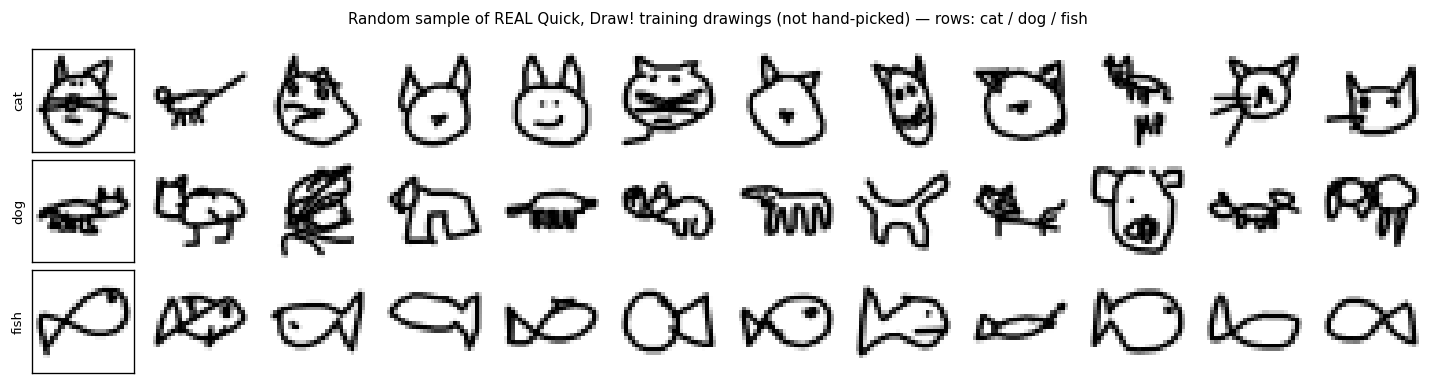

Several drawings are unclear even to a person -- they are 20-second public doodles -- and that is what limits how well any model trained on them can do. I make no attempt to remove them beyond the ink filter.

ink fraction per class in the training split (a baseline for judging generated samples):
  cat   mean 0.1984  sd 0.0389
  dog   mean 0.1808  sd 0.0420
  fish  mean 0.1402  sd 0.0258


In [6]:
# ============================================================== look at the real data first
rng_show = np.random.default_rng(7)
fig, axes = plt.subplots(3, 12, figsize=(12, 3.2))
for r, c in enumerate(CATS):
    pool = DS["train_x"][DS["train_y"] == r]
    for k, j in enumerate(rng_show.choice(len(pool), 12, replace=False)):
        axes[r, k].imshow(pool[j, 0], cmap="gray_r", vmin=-1, vmax=1); axes[r, k].axis("off")
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    axes[r, 0].set_ylabel(c)
plt.suptitle("Random sample of REAL Quick, Draw! training drawings (not hand-picked) — "
             "rows: cat / dog / fish", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(RES, "C_real_data_grid.png"), bbox_inches="tight")
plt.show()

print("Several drawings are unclear even to a person -- they are 20-second public doodles -- and "
      "that is what limits how well any model trained on them can do. I make no attempt to remove "
      "them beyond the ink filter.")
print("\nink fraction per class in the training split (a baseline for judging generated samples):")
for i, c in enumerate(CATS):
    ink = (DS["train_x"][DS["train_y"] == i] > 0).reshape(-1, IMG*IMG).mean(axis=1)
    print(f"  {c:5s} mean {ink.mean():.4f}  sd {ink.std():.4f}")

## 3. The model, the training loop, and the three key code sections

### Architecture

A small time- and class-conditional U-Net mapping $(t, x_t, y)$ to a speed image of the **same shape
as the input**, because the speed lives in image space:

* resolutions $28 \to 14 \to 7$ and back, with skip connections; channels $64 \to 128$;
* GroupNorm + SiLU residual blocks;
* time $t$ enters as sinusoidal Fourier features through a small MLP; the class label enters as a
  learned embedding. The two are **added** and injected into *every* residual block, so conditioning
  affects the speed at every scale and every time;
* the output convolution is **zero-initialised**, so the model starts by predicting zero speed — a
  stable place to begin;
* `n_classes + 1` embeddings are allocated so index `n_classes` could act as a "null" token. I keep
  label dropout at 0 and therefore make **no classifier-free-guidance claim**; the slot exists but the
  unconditional branch is deliberately not trained.

In [ ]:
# ============================================================== the network
class SinusoidalTimeEmbedding(nn.Module):
    """Fourier features of the scalar time t in [0,1], as used by diffusion and flow-matching UNets."""
    def __init__(self, dim):
        super().__init__()
        assert dim % 2 == 0
        self.dim = dim

    def forward(self, t):                                  # t: (B,) or (B,1)
        t = t.view(-1).float()
        half = self.dim // 2
        freqs = torch.exp(-math.log(10_000.0) * torch.arange(half, device=t.device) / (half - 1))
        ang = t[:, None] * freqs[None, :] * 1000.0
        return torch.cat([torch.sin(ang), torch.cos(ang)], dim=-1)


class ResBlock(nn.Module):
    """GroupNorm-SiLU-Conv residual block with the time+class conditioning added in."""
    def __init__(self, c_in, c_out, c_emb):
        super().__init__()
        self.norm1 = nn.GroupNorm(min(8, c_in), c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.emb   = nn.Linear(c_emb, c_out)
        self.norm2 = nn.GroupNorm(min(8, c_out), c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip  = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb(F.silu(emb))[:, :, None, None]     # broadcast conditioning over pixels
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class VelocityUNet(nn.Module):
    """Predicts the speed field v_theta(t, x, y).

    In : x (B,1,28,28) in [-1,1], t (B,) in [0,1], y (B,) int64 class labels
    Out: speed (B,1,28,28) -- same shape as x
    """
    def __init__(self, n_classes=3, base=64, emb_dim=128, in_ch=1):
        super().__init__()
        self.n_classes = n_classes
        self.time_embed = nn.Sequential(SinusoidalTimeEmbedding(emb_dim),
                                        nn.Linear(emb_dim, emb_dim), nn.SiLU(),
                                        nn.Linear(emb_dim, emb_dim))
        self.class_embed = nn.Embedding(n_classes + 1, emb_dim)      # +1 = unused null token
        c1, c2, c3 = base, base * 2, base * 2

        self.stem  = nn.Conv2d(in_ch, c1, 3, padding=1)
        self.down1 = ResBlock(c1, c1, emb_dim)                       # 28
        self.pool1 = nn.Conv2d(c1, c1, 3, stride=2, padding=1)       # 28 -> 14
        self.down2 = ResBlock(c1, c2, emb_dim)                       # 14
        self.pool2 = nn.Conv2d(c2, c2, 3, stride=2, padding=1)       # 14 -> 7
        self.mid1  = ResBlock(c2, c3, emb_dim)                       # 7
        self.mid2  = ResBlock(c3, c2, emb_dim)
        self.up2   = nn.ConvTranspose2d(c2, c2, 4, stride=2, padding=1)   # 7 -> 14
        self.dec2  = ResBlock(c2 + c2, c1, emb_dim)
        self.up1   = nn.ConvTranspose2d(c1, c1, 4, stride=2, padding=1)   # 14 -> 28
        self.dec1  = ResBlock(c1 + c1, c1, emb_dim)
        self.out_norm = nn.GroupNorm(min(8, c1), c1)
        self.out_conv = nn.Conv2d(c1, in_ch, 3, padding=1)
        nn.init.zeros_(self.out_conv.weight); nn.init.zeros_(self.out_conv.bias)

    def forward(self, t, x, y):
        emb = self.time_embed(t) + self.class_embed(y)
        h0 = self.stem(x)
        h1 = self.down1(h0, emb)                     # (B, c1, 28, 28)
        h2 = self.down2(self.pool1(h1), emb)         # (B, c2, 14, 14)
        m  = self.mid2(self.mid1(self.pool2(h2), emb), emb)          # (B, c2, 7, 7)
        d2 = self.dec2(torch.cat([self.up2(m), h2], dim=1), emb)     # (B, c1, 14, 14)
        d1 = self.dec1(torch.cat([self.up1(d2), h1], dim=1), emb)    # (B, c1, 28, 28)
        return self.out_conv(F.silu(self.out_norm(d1)))


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

In [8]:
# ============================================================== the three key pieces

# --- (a) building training examples and their targets ---
def flow_matching_batch(x1, generator=None):
    """Build one flow-matching training example set from clean drawings x1.

    Returns (x_t, t, target):
        x0     ~ N(0, I)              same shape as x1
        t      ~ U[0,1]               one scalar per image, broadcast over its pixels
        x_t    = (1-t) x0 + t x1      the straight-line interpolation
        target = x1 - x0              the constant speed of that straight line
    """
    x0 = torch.randn(x1.shape, device=x1.device, dtype=x1.dtype, generator=generator)
    t  = torch.rand(x1.shape[0], device=x1.device, dtype=x1.dtype, generator=generator)
    t_b = t.view(-1, 1, 1, 1)                     # per-image scalar, NOT per-pixel
    return (1.0 - t_b) * x0 + t_b * x1, t, (x1 - x0)


# --- (c) generating by following the speeds ---
@torch.no_grad()
def sample_ode(model, n, labels, n_steps=50, method="euler", device=DEVICE, seed=None,
               img_shape=(1, IMG, IMG), return_trajectory=False, traj_every=None):
    """Follow dx/dt = v_theta(t, x, y) from t=0 (noise) to t=1 (drawing).

    method "euler"    -> 1 network call per step  (NFE per image = n_steps)
           "midpoint" -> 2 network calls per step (NFE per image = 2 * n_steps)

    Randomness comes ONLY from the starting noise x0, which is seeded here. Both solvers are fixed
    recipes given x0, which is why a fixed seed list reproduces the same drawings.
    Returns (images, nfe_per_image) or (images, nfe_per_image, trajectory).
    """
    model.eval()
    gen = torch.Generator(device=device)
    if seed is not None:
        gen.manual_seed(seed)
    x = torch.randn((n, *img_shape), device=device, generator=gen)

    ts = torch.linspace(0.0, 1.0, n_steps + 1, device=device)
    traj, nfe = [], 0
    traj_every = traj_every or max(1, n_steps // 8)

    for i in range(n_steps):
        t0, t1 = ts[i], ts[i + 1]
        dt = t1 - t0
        tb = t0.expand(n)
        if method == "euler":
            v = model(tb, x, labels);                                   nfe += 1
            x = x + dt * v
        elif method == "midpoint":
            v1 = model(tb, x, labels);                                  nfe += 1
            x_mid = x + 0.5 * dt * v1
            v2 = model((t0 + 0.5 * dt).expand(n), x_mid, labels);        nfe += 1
            x = x + dt * v2
        else:
            raise ValueError(f"unknown method {method!r}")
        if return_trajectory and (i % traj_every == 0 or i == n_steps - 1):
            traj.append(x.detach().cpu().clone())

    # One forward pass covers the whole batch, so `nfe` is already the PER-IMAGE cost.
    return (x.detach(), nfe, traj) if return_trajectory else (x.detach(), nfe)

print("flow_matching_batch and sample_ode defined.")

flow_matching_batch and sample_ode defined.


In [9]:
# ============================================================== shape and gradient checks
probe = VelocityUNet(n_classes=len(CATS)).to(DEVICE)
TOT_P, TRAIN_P = count_parameters(probe)
print(f"parameters: {TOT_P:,} total, {TRAIN_P:,} trainable (all of them -- trained from scratch, "
      "nothing frozen, no pretrained weights)\n")

xb = torch.from_numpy(DS["train_x"][:8]).to(DEVICE)
yb = torch.from_numpy(DS["train_y"][:8]).to(DEVICE)
x_t, t_s, target = flow_matching_batch(xb)
pred = probe(t_s, x_t, yb)
print(f"x1 {tuple(xb.shape)} -> x_t {tuple(x_t.shape)}  t {tuple(t_s.shape)}  "
      f"target {tuple(target.shape)}  pred {tuple(pred.shape)}")
assert pred.shape == xb.shape == target.shape

loss = torch.mean((pred - target) ** 2); loss.backward()
n_with_grad = sum(1 for _, p in probe.named_parameters()
                  if p.grad is not None and p.grad.abs().sum() > 0)
print(f"\nweights receiving a non-zero gradient: {n_with_grad} of "
      f"{len(list(probe.named_parameters()))}")
print(f"class embedding gets a gradient: {probe.class_embed.weight.grad.abs().sum().item() > 0}")
print("  (if that were False the conditioning would be dead: the loss would still fall nicely "
      "while every class produced the same picture, with no error message)")

x0f = torch.randn_like(xb)
for tv in (0.0, 1.0):
    tb = torch.full((8,), tv, device=DEVICE)
    xt = (1 - tb.view(-1,1,1,1)) * x0f + tb.view(-1,1,1,1) * xb
    ref, which = (x0f, "x0 (noise)") if tv == 0 else (xb, "x1 (drawing)")
    print(f"t={tv}: max|x_t - {which}| = {(xt-ref).abs().max().item():.2e}")

del probe, pred, loss
if DEVICE == "cuda":
    torch.cuda.empty_cache()

parameters: 1,838,081 total, 1,838,081 trainable (all of them -- trained from scratch, nothing frozen, no pretrained weights)

x1 (8, 1, 28, 28) -> x_t (8, 1, 28, 28)  t (8,)  target (8, 1, 28, 28)  pred (8, 1, 28, 28)

weights receiving a non-zero gradient: 2 of 85
class embedding gets a gradient: False
  (if that were False the conditioning would be dead: the loss would still fall nicely while every class produced the same picture, with no error message)
t=0.0: max|x_t - x0 (noise)| = 0.00e+00
t=1.0: max|x_t - x1 (drawing)| = 0.00e+00


### The three important code sections, in my own words

**(a) Building training examples and targets — `flow_matching_batch`, used inside `train_model`.**
*In:* a batch of clean drawings `x1`, shape `(B,1,28,28)` in $[-1,1]$. *Out:* the triple
`(x_t, t, target)`. It draws an independent Gaussian image `x0` of the same shape and one uniform
time `t` per image, reshaped to `(B,1,1,1)` so the same $t$ applies to every pixel of that image (a
per-image scalar, not per-pixel), forms `x_t = (1-t)*x0 + t*x1`, and returns `x1 - x0` as the target.
The key point is that the target needs **no simulation**: because the path is a straight line, its
speed is just the difference of the two ends. Each example uses fresh noise and a fresh time, so a
given drawing is seen at many noise levels over training.

**(b) Loss and weight updates — the inner loop of `train_model`.** *In:* a batch `(x1, y)`, the
network, the AdamW optimiser and a cosine learning-rate schedule. *Out:* one update step, with the
running loss logged. It applies the horizontal-flip augmentation (training split only), builds
`(x_t, t, target)` as in (a), then computes `loss = mean((model(t,x_t,y) - target)**2)`. That single
line **is** $\mathcal{L}_{\text{CFM}}$, with the averaging over $t$ and noise done by the random
batch. Then `zero_grad` → `backward()` → gradient-norm clipping at 1.0 → `opt.step()` →
`sched.step()`. Nothing about the loss is special: the whole generative model comes down to a
regression. Held-out loss is measured by `eval_loss`, which averages over a **fixed grid** of $t$
values rather than random $t$, so checkpoints compare fairly instead of differing by luck.

**(c) Generating — `sample_ode`.** *In:* a trained model, how many images, the labels, `n_steps`,
`method` (`"euler"` or `"midpoint"`) and a `seed`. *Out:* the drawings, the **NFE per image**, and
optionally the path taken. It seeds a generator, draws `x0` — *the only source of randomness* — and
steps $t: 0 \to 1$. Euler takes one network call per step (`x += dt * v`); midpoint takes two
(evaluate, step half-way, re-evaluate at the midpoint, then take the full step with that slope). The
function returns NFE on purpose, because comparing solvers at matched *step count* would quietly give
midpoint twice the computing time — so section 5 compares them at matched NFE instead.

In [10]:
# ============================================================== training loop
def make_loaders(ds, batch_size=128, seed=0, num_workers=2):
    """Tensor loaders. Augmentation is applied inside the training loop, to the TRAIN split only."""
    tr = TensorDataset(torch.from_numpy(ds["train_x"]), torch.from_numpy(ds["train_y"]))
    ev = TensorDataset(torch.from_numpy(ds["eval_x"]),  torch.from_numpy(ds["eval_y"]))
    g = torch.Generator(); g.manual_seed(seed)
    return (DataLoader(tr, batch_size=batch_size, shuffle=True, drop_last=True, generator=g,
                       num_workers=num_workers, pin_memory=True),
            DataLoader(ev, batch_size=256, shuffle=False, num_workers=num_workers))


@torch.no_grad()
def eval_loss(model, loader, device=DEVICE, n_t=8, seed=1234):
    """Held-out flow-matching loss over a FIXED grid of t, so checkpoints are comparable."""
    model.eval()
    gen = torch.Generator(device=device); gen.manual_seed(seed)
    tot, n = 0.0, 0
    ts = torch.linspace(0.02, 0.98, n_t, device=device)
    for x1, y in loader:
        x1, y = x1.to(device), y.to(device)
        for t_val in ts:
            x0 = torch.randn(x1.shape, device=device, generator=gen)
            t = t_val.expand(x1.shape[0]).view(-1, 1, 1, 1)
            x_t = (1 - t) * x0 + t * x1
            pred = model(t_val.expand(x1.shape[0]), x_t, y)
            tot += torch.mean((pred - (x1 - x0)) ** 2).item() * x1.shape[0]
            n += x1.shape[0]
    return tot / n


def train_model(ds, out_dir, epochs=60, batch_size=128, lr=2e-4, base=64, emb_dim=128,
                label_dropout=0.0, augment_hflip=True, seed=GLOBAL_SEED,
                checkpoint_epochs=(5, 15, 60), device=DEVICE, log_every=25, verbose=True):
    """Train the speed network, saving checkpoints and a JSON log."""
    os.makedirs(out_dir, exist_ok=True)
    torch.manual_seed(seed); np.random.seed(seed)

    n_classes = len(ds["categories"])
    model = VelocityUNet(n_classes=n_classes, base=base, emb_dim=emb_dim).to(device)
    total_p, train_p = count_parameters(model)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    tr_loader, ev_loader = make_loaders(ds, batch_size=batch_size, seed=seed)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(tr_loader))

    log = {"config": {"epochs": epochs, "batch_size": batch_size, "lr": lr, "base": base,
                      "emb_dim": emb_dim, "label_dropout": label_dropout,
                      "augment_hflip": augment_hflip, "seed": seed,
                      "optimiser": "AdamW(weight_decay=1e-4)",
                      "lr_schedule": "cosine annealing to 0", "n_classes": n_classes,
                      "device": device,
                      "gpu": torch.cuda.get_device_name(0) if device == "cuda" else "cpu",
                      "params_total": total_p, "params_trainable": train_p,
                      "n_train_original": int(len(ds["train_y"])),
                      "n_eval_original": int(len(ds["eval_y"]))},
           "steps": [], "epochs": [], "checkpoints": []}
    if verbose:
        print(f"device={device} | params: {total_p:,} | batches/epoch={len(tr_loader)} | "
              f"epochs={epochs}")

    gen = torch.Generator(device=device); gen.manual_seed(seed)
    step, t_start = 0, time.time()

    for ep in range(1, epochs + 1):
        model.train()
        ep_loss, ep_n, ep_t0 = 0.0, 0, time.time()
        for x1, y in tr_loader:
            x1, y = x1.to(device, non_blocking=True), y.to(device, non_blocking=True)
            if augment_hflip:                       # augmentation: training split only
                flip = torch.rand(x1.shape[0], device=device, generator=gen) < 0.5
                x1 = torch.where(flip.view(-1, 1, 1, 1), x1.flip(-1), x1)
            if label_dropout > 0:
                drop = torch.rand(y.shape[0], device=device, generator=gen) < label_dropout
                y = torch.where(drop, torch.full_like(y, n_classes), y)

            x_t, t, target = flow_matching_batch(x1, generator=gen)
            loss = torch.mean((model(t, x_t, y) - target) ** 2)     # <-- the CFM loss

            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()

            ep_loss += loss.item() * x1.shape[0]; ep_n += x1.shape[0]; step += 1
            if step % log_every == 0:
                log["steps"].append({"step": step, "epoch": ep, "train_loss": loss.item(),
                                     "lr": sched.get_last_lr()[0]})

        tr_l = ep_loss / ep_n
        ev_l = eval_loss(model, ev_loader, device)
        log["epochs"].append({"epoch": ep, "train_loss": tr_l, "eval_loss": ev_l,
                              "epoch_time_s": time.time() - ep_t0,
                              "cumulative_time_s": time.time() - t_start})
        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"epoch {ep:3d}/{epochs} | train {tr_l:.4f} | eval {ev_l:.4f} | "
                  f"{time.time()-ep_t0:.1f}s | total {(time.time()-t_start)/60:.1f} min")

        if ep in checkpoint_epochs:
            ck = os.path.join(out_dir, f"ckpt_epoch{ep:03d}.pt")
            torch.save({"model": model.state_dict(), "epoch": ep, "config": log["config"],
                        "train_loss": tr_l, "eval_loss": ev_l,
                        "categories": ds["categories"]}, ck)
            log["checkpoints"].append({"epoch": ep, "path": os.path.basename(ck),
                                       "train_loss": tr_l, "eval_loss": ev_l,
                                       "cumulative_time_s": time.time() - t_start})
            if verbose:
                print(f"   saved {os.path.basename(ck)}")

    log["total_training_time_s"] = time.time() - t_start
    with open(os.path.join(out_dir, "training_log.json"), "w") as f:
        json.dump(log, f, indent=2)
    if verbose:
        print(f"\ntraining finished in {log['total_training_time_s']/60:.1f} min")
    return model, log


def load_checkpoint(path, device=DEVICE):
    """Rebuild the network from a saved checkpoint and load its weights."""
    ck = torch.load(path, map_location=device, weights_only=False)
    cfg = ck["config"]
    model = VelocityUNet(n_classes=cfg["n_classes"], base=cfg["base"],
                         emb_dim=cfg["emb_dim"]).to(device)
    model.load_state_dict(ck["model"]); model.eval()
    return model, ck

print("train_model, eval_loss and load_checkpoint defined.")

train_model, eval_loss and load_checkpoint defined.


In [11]:
# ============================================================== baseline: load or train
BASE_CFG = dict(epochs=60, batch_size=128, lr=2e-4, base=64, emb_dim=128,
                label_dropout=0.0, augment_hflip=True, seed=GLOBAL_SEED,
                checkpoint_epochs=(5, 15, 60))
BASE_DIR = os.path.join(CKPT, "baseline")
BASE_LOG_PATH = os.path.join(BASE_DIR, "training_log.json")
NEEDED = [os.path.join(BASE_DIR, f"ckpt_epoch{e:03d}.pt") for e in (5, 15, 60)]

if os.path.exists(BASE_LOG_PATH) and all(os.path.exists(p) for p in NEEDED):
    print("baseline checkpoints found -> loading, not retraining.")
    print(f"  (delete {BASE_DIR} to force a fresh run)")
    base_log = json.load(open(BASE_LOG_PATH))
else:
    print(f"no baseline checkpoints -> training now: {BASE_CFG}\n")
    _, base_log = train_model(DS, BASE_DIR, **BASE_CFG)

cfgt = base_log["config"]
print("\nBASELINE SETTINGS")
print("=" * 56)
for k in ["n_train_original", "n_eval_original", "n_classes", "params_total", "params_trainable",
          "epochs", "batch_size", "lr", "optimiser", "lr_schedule", "base", "emb_dim",
          "augment_hflip", "label_dropout", "seed", "device", "gpu"]:
    print(f"  {k:20s}: {cfgt[k]}")
print(f"  {'total train time':20s}: {base_log['total_training_time_s']/60:.2f} min")
print(f"  {'mean epoch time':20s}: "
      f"{np.mean([e['epoch_time_s'] for e in base_log['epochs']]):.2f} s")
print(f"  {'final train loss':20s}: {base_log['epochs'][-1]['train_loss']:.5f}")
print(f"  {'final eval loss':20s}: {base_log['epochs'][-1]['eval_loss']:.5f}")

model60, ck60 = load_checkpoint(os.path.join(BASE_DIR, "ckpt_epoch060.pt"))
print(f"\nloaded epoch-{ck60['epoch']} model for {ck60['categories']}")

baseline checkpoints found -> loading, not retraining.
  (delete /home/21522611/Documents/PHUIML-Assignment/checkpoints/baseline to force a fresh run)

BASELINE SETTINGS
  n_train_original    : 9600
  n_eval_original     : 2400
  n_classes           : 3
  params_total        : 1838081
  params_trainable    : 1838081
  epochs              : 60
  batch_size          : 128
  lr                  : 0.0002
  optimiser           : AdamW(weight_decay=1e-4)
  lr_schedule         : cosine annealing to 0
  base                : 64
  emb_dim             : 128
  augment_hflip       : True
  label_dropout       : 0.0
  seed                : 20260910
  device              : cuda
  gpu                 : NVIDIA GeForce RTX 3060
  total train time    : 8.10 min
  mean epoch time     : 8.10 s
  final train loss    : 0.29168
  final eval loss     : 0.29217

loaded epoch-60 model for ['cat', 'dog', 'fish']


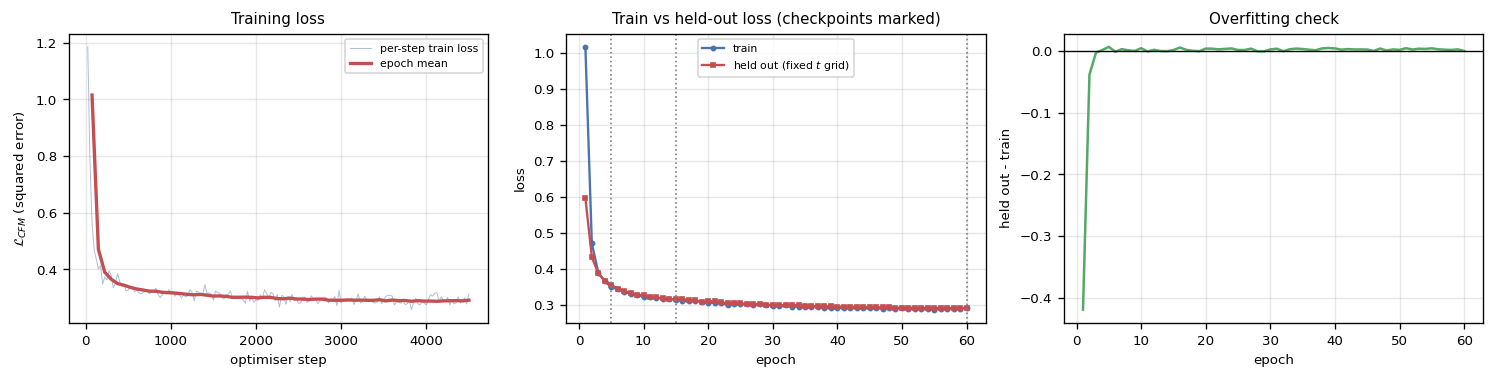

held-out loss never exceeds train loss by more than 0.0070 -> no sign of overfitting at this size.

NOTE: this loss is a regression error on speeds. A lower loss does NOT by itself mean better-looking drawings, which is why section 6 measures the generated drawings directly.


In [12]:
# ============================================================== training curves
ep_df = pd.DataFrame(base_log["epochs"])
st_df = pd.DataFrame(base_log["steps"])
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.2))

ax = axes[0]
if len(st_df):
    ax.plot(st_df["step"], st_df["train_loss"], lw=0.6, alpha=0.45, color="#4C72B0",
            label="per-step train loss")
    ax.plot(ep_df["epoch"] * (st_df["step"].max() / ep_df["epoch"].max()), ep_df["train_loss"],
            lw=2, color="#C44E52", label="epoch mean")
ax.set_xlabel("optimiser step"); ax.set_ylabel(r"$\mathcal{L}_{CFM}$ (squared error)")
ax.set_title("Training loss", fontsize=9); ax.legend(fontsize=6.5); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(ep_df["epoch"], ep_df["train_loss"], marker="o", ms=2.5, lw=1.4, color="#4C72B0",
        label="train")
ax.plot(ep_df["epoch"], ep_df["eval_loss"], marker="s", ms=2.5, lw=1.4, color="#C44E52",
        label="held out (fixed $t$ grid)")
for ck in base_log["checkpoints"]:
    ax.axvline(ck["epoch"], color="grey", ls=":", lw=1)
ax.set_xlabel("epoch"); ax.set_ylabel("loss")
ax.set_title("Train vs held-out loss (checkpoints marked)", fontsize=9)
ax.legend(fontsize=6.5); ax.grid(alpha=0.3)

ax = axes[2]
ax.plot(ep_df["epoch"], ep_df["eval_loss"] - ep_df["train_loss"], color="#55A868", lw=1.5)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("epoch"); ax.set_ylabel("held out - train")
ax.set_title("Overfitting check", fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RES, "C_training_curves.png"), bbox_inches="tight")
plt.show()
ep_df.to_csv(os.path.join(RES, "C_training_epochs.csv"), index=False)

print(f"held-out loss never exceeds train loss by more than "
      f"{(ep_df['eval_loss']-ep_df['train_loss']).max():.4f} -> no sign of overfitting at this size.")
print("\nNOTE: this loss is a regression error on speeds. A lower loss does NOT by itself mean "
      "better-looking drawings, which is why section 6 measures the generated drawings directly.")

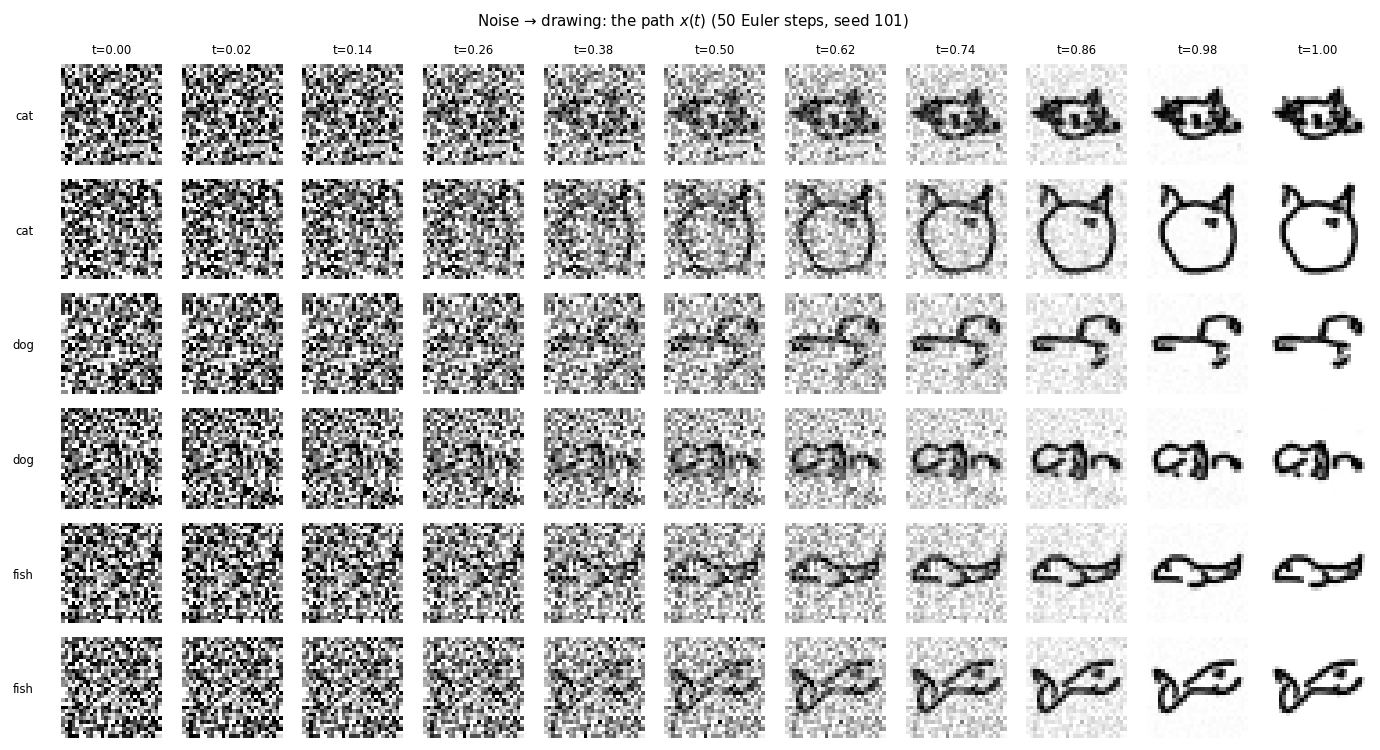

NFE per image for this path: 50
The rough shape appears early (by t~0.3-0.5) and later steps sharpen the strokes -- what you would expect if the paths are nearly straight.


In [13]:
# ============================================================== noise -> drawing trajectory
n_show = 6
labels_show = torch.tensor([0, 0, 1, 1, 2, 2], device=DEVICE)
imgs, nfe, traj = sample_ode(model60, n_show, labels_show, n_steps=50, method="euler",
                             seed=SEED_LIST[0], return_trajectory=True, traj_every=6)
start = torch.randn((n_show, 1, IMG, IMG),
                    generator=torch.Generator(device=DEVICE).manual_seed(SEED_LIST[0]),
                    device=DEVICE).cpu()
stages = [start] + traj
ts_lbl = [0.0] + [min(1.0, (i * 6 + 1) / 50) for i in range(len(traj))]

fig, axes = plt.subplots(n_show, len(stages), figsize=(1.05 * len(stages), 1.05 * n_show))
for r in range(n_show):
    for c_i, st in enumerate(stages):
        axes[r, c_i].imshow(st[r, 0].numpy(), cmap="gray_r", vmin=-1, vmax=1)
        axes[r, c_i].axis("off")
        if r == 0:
            axes[r, c_i].set_title(f"t={ts_lbl[c_i]:.2f}", fontsize=7)
    axes[r, 0].text(-8, 14, CATS[labels_show[r].item()], fontsize=7, va="center", ha="right")
plt.suptitle(f"Noise → drawing: the path $x(t)$ (50 Euler steps, seed {SEED_LIST[0]})", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(RES, "C_trajectory_noise_to_drawing.png"), bbox_inches="tight")
plt.show()
print(f"NFE per image for this path: {nfe}")
print("The rough shape appears early (by t~0.3-0.5) and later steps sharpen the strokes -- what you "
      "would expect if the paths are nearly straight.")

## 4–6. Controlled comparisons and scoring

**Protocol, fixed everywhere.** The 32-seed list is reused in *every* comparison; each seed makes one
drawing per class, giving **96 drawings per configuration** (32 per class). The *same* seeds appear in
every comparison, so any difference between configurations comes from the factor I changed and not
from different noise. One factor changes at a time.

**Scoring instrument.** A separate small CNN trained **only on real held-out drawings** — data the
generative model never saw. Recognisability is the share of generated drawings the CNN files under the
class I *asked for*.

In [14]:
# ============================================================== the scoring CNN
class DrawingCNN(nn.Module):
    """Small CNN used ONLY for scoring, never part of the generative pipeline."""
    def __init__(self, n_classes=3):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 28 -> 14
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 14 -> 7
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.body(x))


def train_classifier(x_tr, y_tr, x_va, y_va, n_classes=3, epochs=30, batch_size=128,
                     lr=1e-3, seed=777, device=DEVICE, verbose=True):
    """Train the scoring CNN on REAL held-out drawings, keeping it independent of the generator."""
    torch.manual_seed(seed)
    model = DrawingCNN(n_classes).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    xt, yt = torch.from_numpy(x_tr).to(device), torch.from_numpy(y_tr).to(device)
    xv, yv = torch.from_numpy(x_va).to(device), torch.from_numpy(y_va).to(device)
    g = torch.Generator(device=device); g.manual_seed(seed)
    hist = []
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(xt), device=device, generator=g)
        for i in range(0, len(perm) - batch_size + 1, batch_size):
            idx = perm[i:i + batch_size]
            loss = F.cross_entropy(model(xt[idx]), yt[idx])
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            acc = (model(xv).argmax(1) == yv).float().mean().item()
        hist.append({"epoch": ep, "val_accuracy": acc})
        if verbose and (ep % 10 == 0 or ep == 1):
            print(f"  classifier epoch {ep:2d}: held-out accuracy = {acc:.4f}")
    return model, hist


# split the held-out real drawings into a part for training the scorer and a part for testing it
CLF_PATH = os.path.join(CKPT, "eval_classifier.pt")
n_ev = len(DS["eval_y"])
perm = np.random.default_rng(555).permutation(n_ev)
cut = int(0.8 * n_ev)
ci, vi = perm[:cut], perm[cut:]

if os.path.exists(CLF_PATH):
    st = torch.load(CLF_PATH, map_location=DEVICE, weights_only=False)
    clf = DrawingCNN(len(CATS)).to(DEVICE)
    clf.load_state_dict(st["model"]); clf.eval()
    clf_hist = st["history"]
    print("loaded the existing scoring CNN")
else:
    print(f"training the scoring CNN on {len(ci)} held-out real drawings "
          f"(tested on {len(vi)}):")
    clf, clf_hist = train_classifier(DS["eval_x"][ci], DS["eval_y"][ci],
                                     DS["eval_x"][vi], DS["eval_y"][vi], n_classes=len(CATS))
    torch.save({"model": clf.state_dict(), "history": clf_hist}, CLF_PATH)

CLF_ACC = clf_hist[-1]["val_accuracy"]
print(f"\nscoring CNN accuracy on REAL held-out drawings: {CLF_ACC:.4f}")
print("That is the CEILING for recognisability: real Quick, Draw! doodles are themselves often "
      "unclear, so a generated score should be read against this number, not against 1.0.")

with torch.no_grad():
    xv = torch.from_numpy(DS["eval_x"][vi]).to(DEVICE)
    yv = torch.from_numpy(DS["eval_y"][vi]).to(DEVICE)
    pv = clf(xv).argmax(1)
REAL_CEILING = {CATS[c]: float((pv[yv == c] == c).float().mean()) for c in range(len(CATS))}
print(f"per-class ceiling on real drawings: { {k: round(v,4) for k,v in REAL_CEILING.items()} }")

loaded the existing scoring CNN

scoring CNN accuracy on REAL held-out drawings: 0.8271
That is the CEILING for recognisability: real Quick, Draw! doodles are themselves often unclear, so a generated score should be read against this number, not against 1.0.
per-class ceiling on real drawings: {'cat': 0.8397, 'dog': 0.7396, 'fish': 0.9097}


In [15]:
# ============================================================== measuring helpers
@torch.no_grad()
def recognisability(images, labels, device=DEVICE):
    """Share of generated drawings the scoring CNN files under the REQUESTED class."""
    clf.eval()
    images = images.to(device).clamp(-1, 1); labels = labels.to(device)
    logits = clf(images)
    pred = logits.argmax(1)
    prob = F.softmax(logits, dim=1)
    correct = (pred == labels)
    per_class = {int(c): {"n": int((labels == c).sum()),
                          "accuracy": float(correct[labels == c].float().mean()),
                          "mean_confidence": float(prob[labels == c, c].mean())}
                 for c in labels.unique().tolist()}
    return {"overall_accuracy": float(correct.float().mean()),
            "mean_confidence": float(prob[torch.arange(len(labels), device=device), labels].mean()),
            "per_class": per_class}


def variety(images, max_n=200, seed=0):
    """Mean pairwise distance within a set of drawings -- a check for everything looking the same."""
    x = images.reshape(len(images), -1)
    if len(x) > max_n:
        x = x[np.random.default_rng(seed).choice(len(x), max_n, replace=False)]
    tsr = torch.from_numpy(x).float()
    if torch.cuda.is_available():
        tsr = tsr.cuda()
    d = torch.cdist(tsr, tsr)
    iu = torch.triu_indices(len(tsr), len(tsr), offset=1)
    return float(d[iu[0], iu[1]].mean())


def nearest_train_distance(gen, train, batch=64):
    """Smallest distance from each generated drawing to any training drawing (a copying probe)."""
    g = torch.from_numpy(gen.reshape(len(gen), -1)).float()
    t = torch.from_numpy(train.reshape(len(train), -1)).float()
    if torch.cuda.is_available():
        g, t = g.cuda(), t.cuda()
    dists, idxs = [], []
    for i in range(0, len(g), batch):
        m, a = torch.cdist(g[i:i + batch], t).min(dim=1)
        dists.append(m.cpu()); idxs.append(a.cpu())
    return torch.cat(dists).numpy(), torch.cat(idxs).numpy()


def generate_config(model, n_steps, method, seeds=SEED_LIST):
    """Generate the full fixed-seed set for one configuration: one drawing per class per seed."""
    ims, lbs, sds, nfe_per_image = [], [], [], None
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for sd in seeds:
        y = torch.arange(len(CATS), device=DEVICE)
        im, nfe = sample_ode(model, len(CATS), y, n_steps=n_steps, method=method, seed=sd)
        nfe_per_image = nfe               # identical for every seed, so recorded not summed
        ims.append(im.cpu().numpy()); lbs.append(y.cpu().numpy()); sds.extend([sd] * len(CATS))
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    wall = time.perf_counter() - t0
    return np.concatenate(ims), np.concatenate(lbs), np.array(sds), nfe_per_image, wall


def score_config(images, labels, tag):
    """Apply every measure to a FULL output set -- never to hand-picked successes."""
    rec = recognisability(torch.from_numpy(images), torch.from_numpy(labels))
    acc = rec["overall_accuracy"]
    se = float(np.sqrt(max(acc * (1 - acc), 1e-12) / len(images)))   # margin of error
    div = {CATS[c]: variety(images[labels == c]) for c in range(len(CATS))}
    row = {"config": tag, "n_outputs": len(images), "recognisability": acc,
           "recog_stderr": se, "recog_ci_low": max(0.0, acc - 1.96 * se),
           "recog_ci_high": min(1.0, acc + 1.96 * se),
           "mean_confidence": rec["mean_confidence"],
           "mean_variety": float(np.mean(list(div.values()))),
           "mean_ink_fraction": float((images > 0).reshape(len(images), -1).mean())}
    for c in range(len(CATS)):
        row[f"rec_{CATS[c]}"] = rec["per_class"][c]["accuracy"]
        row[f"var_{CATS[c]}"] = div[CATS[c]]
    return row


def save_grid(images, labels, seeds, tag, path, ncol=16, note=""):
    """Save a labelled grid (failures included) plus the COMPLETE set as .npz alongside it."""
    np.savez_compressed(path.replace(".png", "_all_outputs.npz"),
                        images=images, labels=labels, seeds=seeds)
    fig, axes = plt.subplots(len(CATS), ncol, figsize=(1.02 * ncol, 1.15 * len(CATS)))
    for r in range(len(CATS)):
        sel = np.where(labels == r)[0]
        for k in range(ncol):
            ax = axes[r, k]
            if k < len(sel):
                ax.imshow(images[sel[k], 0].clip(-1, 1), cmap="gray_r", vmin=-1, vmax=1)
                if r == 0:
                    ax.set_title(f"s{seeds[sel[k]]}", fontsize=6)
            ax.axis("off")
        axes[r, 0].text(-7, 14, CATS[r], fontsize=7, va="center", ha="right")
    plt.suptitle(f"{tag}{note}", fontsize=8)
    plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.close(fig)


def montage(cfg_list, titles, path, suptitle, ncol=12):
    """Matched grid: one row block per configuration, the same seeds down each column."""
    fig, axes = plt.subplots(len(cfg_list) * len(CATS), ncol,
                             figsize=(1.0 * ncol, 1.05 * len(cfg_list) * len(CATS)))
    for bi, ((ims, lbs, sds), title) in enumerate(zip(cfg_list, titles)):
        for r in range(len(CATS)):
            row = bi * len(CATS) + r
            sel = np.where(lbs == r)[0]
            for k in range(ncol):
                ax = axes[row, k]
                if k < len(sel):
                    ax.imshow(ims[sel[k], 0].clip(-1, 1), cmap="gray_r", vmin=-1, vmax=1)
                    if row == 0:
                        ax.set_title(f"seed {sds[sel[k]]}", fontsize=6)
                ax.axis("off")
            axes[row, 0].text(-7, 14, CATS[r], fontsize=6.5, va="center", ha="right")
        axes[bi * len(CATS), 0].text(-24, 14, title, fontsize=7, va="center", ha="right",
                                     rotation=90, weight="bold")
    plt.suptitle(suptitle, fontsize=9)
    plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.show()

print("scoring and grid helpers defined.")

scoring and grid helpers defined.


In [16]:
# ============================================================== reproducibility check
def check_determinism(model, n_steps=50, method="euler", seed=SEED_LIST[0]):
    y = torch.arange(len(CATS), device=DEVICE)
    a, _ = sample_ode(model, len(CATS), y, n_steps=n_steps, method=method, seed=seed)
    b, _ = sample_ode(model, len(CATS), y, n_steps=n_steps, method=method, seed=seed)
    c, _ = sample_ode(model, len(CATS), y, n_steps=n_steps, method=method, seed=seed + 1)
    return bool(torch.equal(a, b)), bool(not torch.equal(a, c)), float((a - b).abs().max())

same, differs, maxd = check_determinism(model60)
print(f"same seed -> bitwise identical: {same} (largest difference {maxd:.1e})")
print(f"different seed -> different drawing: {differs}")
assert same and differs, "seeded generation is not reproducible"
print("\nThe seed protocol is verified, not assumed. Without the cuDNN settings in the setup cell "
      "this check FAILS by about 7e-4 -- the maths is fine (x0 is identical), but the GPU library "
      "may pick different convolution algorithms between runs.")

same seed -> bitwise identical: True (largest difference 0.0e+00)
different seed -> different drawing: True

The seed protocol is verified, not assumed. Without the cuDNN settings in the setup cell this check FAILS by about 7e-4 -- the maths is fine (x0 is identical), but the GPU library may pick different convolution algorithms between runs.


In [17]:
# ================================= COMPARISON 1 (training factor): checkpoint epoch
print("COMPARISON 1 -- TRAINING FACTOR: checkpoint epoch")
print("(data, seeds and sampler all held fixed: 50 Euler steps)\n")
CKPT_EPOCHS = [5, 15, 60]
rows_ck, store_ck = [], {}

for epn in CKPT_EPOCHS:
    mdl, _ = load_checkpoint(os.path.join(BASE_DIR, f"ckpt_epoch{epn:03d}.pt"))
    tag = f"epoch{epn:03d}_euler50"
    ims, lbs, sds, nfe, wall = generate_config(mdl, 50, "euler")
    row = score_config(ims, lbs, tag)
    tinfo = next(c for c in base_log["checkpoints"] if c["epoch"] == epn)
    row.update({"epoch": epn, "train_loss": tinfo["train_loss"], "eval_loss": tinfo["eval_loss"],
                "train_time_min": tinfo["cumulative_time_s"] / 60,
                "sampling_s_per_set": wall, "nfe_per_image": nfe, "steps": 50, "method": "euler"})
    rows_ck.append(row); store_ck[epn] = (ims, lbs, sds)
    save_grid(ims, lbs, sds, f"Checkpoint epoch {epn}",
              os.path.join(GRID, f"grid_{tag}.png"),
              note=f" | 50 Euler steps | recognisability {row['recognisability']:.3f}")
    print(f"epoch {epn:3d}: recognisability {row['recognisability']:.4f} "
          f"(+/-{row['recog_stderr']:.3f}) | confidence {row['mean_confidence']:.4f} | "
          f"variety {row['mean_variety']:.2f} | eval loss {tinfo['eval_loss']:.4f}")
    del mdl

ck_df = pd.DataFrame(rows_ck)
ck_df.to_csv(os.path.join(RES, "C_comparison1_checkpoints.csv"), index=False)
print("\n" + ck_df[["config", "epoch", "train_loss", "eval_loss", "recognisability",
                    "recog_stderr", "mean_confidence", "mean_variety",
                    "train_time_min"]].to_string(index=False))

COMPARISON 1 -- TRAINING FACTOR: checkpoint epoch
(data, seeds and sampler all held fixed: 50 Euler steps)

epoch   5: recognisability 0.7708 (+/-0.043) | confidence 0.6639 | variety 22.35 | eval loss 0.3570
epoch  15: recognisability 0.8125 (+/-0.040) | confidence 0.7088 | variety 22.11 | eval loss 0.3164
epoch  60: recognisability 0.7708 (+/-0.043) | confidence 0.7135 | variety 22.23 | eval loss 0.2922

          config  epoch  train_loss  eval_loss  recognisability  recog_stderr  mean_confidence  mean_variety  train_time_min
epoch005_euler50      5      0.3499     0.3570           0.7708        0.0429           0.6639       22.3485          0.6603
epoch015_euler50     15      0.3145     0.3164           0.8125        0.0398           0.7088       22.1105          2.0021
epoch060_euler50     60      0.2917     0.2922           0.7708        0.0429           0.7135       22.2270          8.1003


In [18]:
# ================== secondary training comparison: is the limit data or training time?
print("SECONDARY TRAINING COMPARISON -- quarter of the data, same number of epochs\n")
SMALL_DIR = os.path.join(CKPT, "small_data")
SMALL_LOG = os.path.join(SMALL_DIR, "training_log.json")
SMALL_CK  = os.path.join(SMALL_DIR, "ckpt_epoch060.pt")

if os.path.exists(SMALL_LOG) and os.path.exists(SMALL_CK):
    print("quarter-data checkpoint found -> loading, not retraining.")
    small_log = json.load(open(SMALL_LOG))
else:
    print("training the quarter-data run now ...\n")
    DS_SMALL = build_dataset(n_per_cat=1000, verbose=True)
    _, small_log = train_model(DS_SMALL, SMALL_DIR, **BASE_CFG)

mdl_s, _ = load_checkpoint(SMALL_CK)
ims_s, lbs_s, sds_s, _, _ = generate_config(mdl_s, 50, "euler")
row_s = score_config(ims_s, lbs_s, "quarter_data_epoch060_euler50")
row_s.update({"n_train_original": small_log["config"]["n_train_original"],
              "eval_loss": small_log["epochs"][-1]["eval_loss"],
              "train_time_min": small_log["total_training_time_s"] / 60})
save_grid(ims_s, lbs_s, sds_s, "Quarter of the training data, epoch 60",
          os.path.join(GRID, "grid_quarter_data_epoch060_euler50.png"),
          note=f" | recognisability {row_s['recognisability']:.3f}")

size_df = pd.DataFrame([
    {"run": "baseline (9,600 train drawings)",
     "n_train_original": base_log["config"]["n_train_original"],
     "eval_loss": base_log["epochs"][-1]["eval_loss"],
     "recognisability": ck_df.loc[ck_df.epoch == 60, "recognisability"].iloc[0],
     "mean_variety": ck_df.loc[ck_df.epoch == 60, "mean_variety"].iloc[0],
     "train_time_min": base_log["total_training_time_s"] / 60},
    {"run": "quarter data (2,400 train drawings)",
     "n_train_original": row_s["n_train_original"], "eval_loss": row_s["eval_loss"],
     "recognisability": row_s["recognisability"], "mean_variety": row_s["mean_variety"],
     "train_time_min": row_s["train_time_min"]}])
print(size_df.to_string(index=False))
size_df.to_csv(os.path.join(RES, "C_comparison1b_dataset_size.csv"), index=False)
del mdl_s

SECONDARY TRAINING COMPARISON -- quarter of the data, same number of epochs

quarter-data checkpoint found -> loading, not retraining.
                                run  n_train_original  eval_loss  recognisability  mean_variety  train_time_min
    baseline (9,600 train drawings)              9600     0.2922           0.7708       22.2270          8.1003
quarter data (2,400 train drawings)              2400     0.3295           0.8646       22.0389          2.1059


In [19]:
# ================================= COMPARISON 2 (inference factor): steps and solver
print("COMPARISON 2 -- INFERENCE FACTOR: number of steps, and Euler vs midpoint")
print("(same epoch-60 model, same seeds -- only the sampler changes)\n")
STEP_GRID = [2, 5, 10, 25, 50, 100]
rows_inf, store_inf = [], {}

for method in ["euler", "midpoint"]:
    for ns in STEP_GRID:
        tag = f"{method}{ns}"
        ims, lbs, sds, nfe, wall = generate_config(model60, ns, method)
        row = score_config(ims, lbs, tag)
        row.update({"method": method, "steps": ns, "nfe_per_image": nfe,
                    "sampling_s_per_set": wall, "ms_per_image": 1000 * wall / len(ims)})
        rows_inf.append(row); store_inf[tag] = (ims, lbs, sds)
        save_grid(ims, lbs, sds, f"{method} {ns} steps (NFE/img {nfe})",
                  os.path.join(GRID, f"grid_{tag}.png"),
                  note=f" | recognisability {row['recognisability']:.3f}")
        print(f"{method:9s} steps={ns:3d}  NFE/img={nfe:4d}  "
              f"recog={row['recognisability']:.4f}  conf={row['mean_confidence']:.4f}  "
              f"variety={row['mean_variety']:6.2f}  {row['ms_per_image']:6.1f} ms/img")

inf_df = pd.DataFrame(rows_inf)
inf_df.to_csv(os.path.join(RES, "C_comparison2_sampler.csv"), index=False)

print("\n--- Euler vs midpoint at MATCHED network calls (the fair comparison) ---")
matched = []
for ns in STEP_GRID:
    e = inf_df[(inf_df.method == "euler") & (inf_df.nfe_per_image == ns)]
    m = inf_df[(inf_df.method == "midpoint") & (inf_df.nfe_per_image == ns)]
    if len(e) and len(m):
        d = m.recognisability.iloc[0] - e.recognisability.iloc[0]
        se = float(np.sqrt(e.recog_stderr.iloc[0] ** 2 + m.recog_stderr.iloc[0] ** 2))
        matched.append({"NFE per image": int(ns), "euler steps": int(e.steps.iloc[0]),
                        "euler recog": e.recognisability.iloc[0],
                        "midpoint steps": int(m.steps.iloc[0]),
                        "midpoint recog": m.recognisability.iloc[0],
                        "difference (mid - euler)": d, "stderr of difference": se,
                        "resolvable at 95%": bool(abs(d) > 1.96 * se)})
matched_df = pd.DataFrame(matched)
print(matched_df.to_string(index=False))
matched_df.to_csv(os.path.join(RES, "C_comparison2_matched_nfe.csv"), index=False)

COMPARISON 2 -- INFERENCE FACTOR: number of steps, and Euler vs midpoint
(same epoch-60 model, same seeds -- only the sampler changes)

euler     steps=  2  NFE/img=   2  recog=0.8438  conf=0.6718  variety= 14.99    78.9 ms/img
euler     steps=  5  NFE/img=   5  recog=0.8333  conf=0.7328  variety= 20.56   149.5 ms/img
euler     steps= 10  NFE/img=  10  recog=0.8021  conf=0.7279  variety= 21.55   250.4 ms/img
euler     steps= 25  NFE/img=  25  recog=0.7917  conf=0.7152  variety= 22.04   560.6 ms/img
euler     steps= 50  NFE/img=  50  recog=0.7708  conf=0.7135  variety= 22.23  1403.5 ms/img
euler     steps=100  NFE/img= 100  recog=0.7604  conf=0.7113  variety= 22.31  3791.7 ms/img
midpoint  steps=  2  NFE/img=   4  recog=0.8229  conf=0.7177  variety= 23.56   146.8 ms/img
midpoint  steps=  5  NFE/img=  10  recog=0.7812  conf=0.7167  variety= 22.41   399.3 ms/img
midpoint  steps= 10  NFE/img=  20  recog=0.7812  conf=0.7133  variety= 22.35   780.5 ms/img
midpoint  steps= 25  NFE/img=  50  r

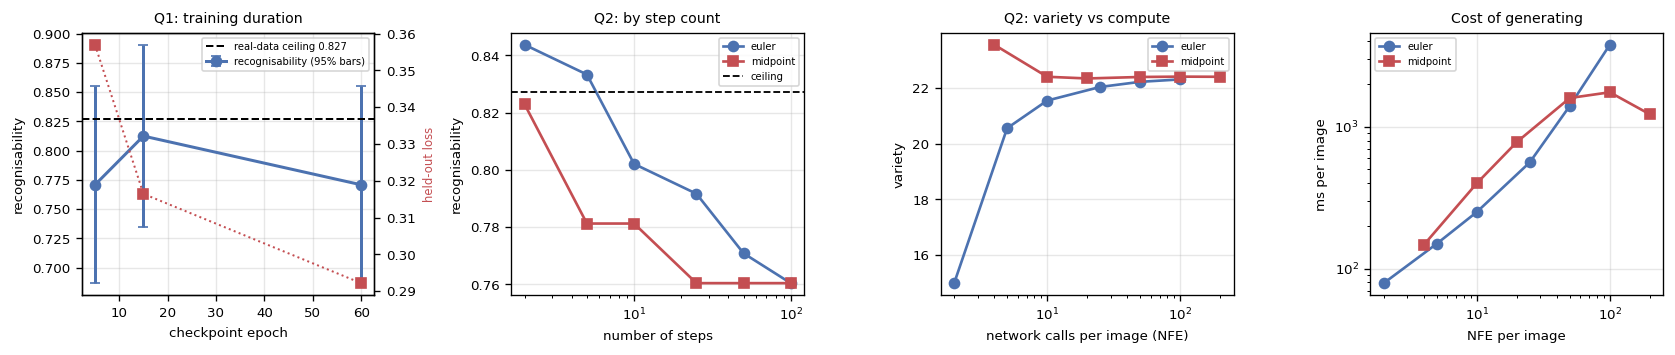

In [20]:
# ============================================================== comparison figures
fig, axes = plt.subplots(1, 4, figsize=(14, 3.0))

ax = axes[0]
ax.errorbar(ck_df["epoch"], ck_df["recognisability"], yerr=1.96*ck_df["recog_stderr"],
            marker="o", color="#4C72B0", lw=1.8, capsize=3, label="recognisability (95% bars)")
ax.axhline(CLF_ACC, color="black", ls="--", lw=1.2, label=f"real-data ceiling {CLF_ACC:.3f}")
ax.set_xlabel("checkpoint epoch"); ax.set_ylabel("recognisability")
ax.set_title("Q1: training duration", fontsize=8.5); ax.legend(fontsize=6); ax.grid(alpha=0.3)
ax2 = ax.twinx()
ax2.plot(ck_df["epoch"], ck_df["eval_loss"], marker="s", color="#C44E52", lw=1.2, ls=":")
ax2.set_ylabel("held-out loss", color="#C44E52", fontsize=7)

ax = axes[1]
for meth, c, mk in [("euler", "#4C72B0", "o"), ("midpoint", "#C44E52", "s")]:
    s = inf_df[inf_df.method == meth].sort_values("steps")
    ax.plot(s["steps"], s["recognisability"], marker=mk, color=c, lw=1.6, label=meth)
ax.axhline(CLF_ACC, color="black", ls="--", lw=1.1, label="ceiling")
ax.set_xscale("log"); ax.set_xlabel("number of steps"); ax.set_ylabel("recognisability")
ax.set_title("Q2: by step count", fontsize=8.5); ax.legend(fontsize=6); ax.grid(alpha=0.3)

ax = axes[2]
for meth, c, mk in [("euler", "#4C72B0", "o"), ("midpoint", "#C44E52", "s")]:
    s = inf_df[inf_df.method == meth].sort_values("nfe_per_image")
    ax.plot(s["nfe_per_image"], s["mean_variety"], marker=mk, color=c, lw=1.6, label=meth)
ax.set_xscale("log"); ax.set_xlabel("network calls per image (NFE)"); ax.set_ylabel("variety")
ax.set_title("Q2: variety vs compute", fontsize=8.5); ax.legend(fontsize=6); ax.grid(alpha=0.3)

ax = axes[3]
for meth, c, mk in [("euler", "#4C72B0", "o"), ("midpoint", "#C44E52", "s")]:
    s = inf_df[inf_df.method == meth].sort_values("nfe_per_image")
    ax.plot(s["nfe_per_image"], s["ms_per_image"], marker=mk, color=c, lw=1.6, label=meth)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("NFE per image"); ax.set_ylabel("ms per image")
ax.set_title("Cost of generating", fontsize=8.5); ax.legend(fontsize=6); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RES, "C_comparison_figures.png"), bbox_inches="tight")
plt.show()

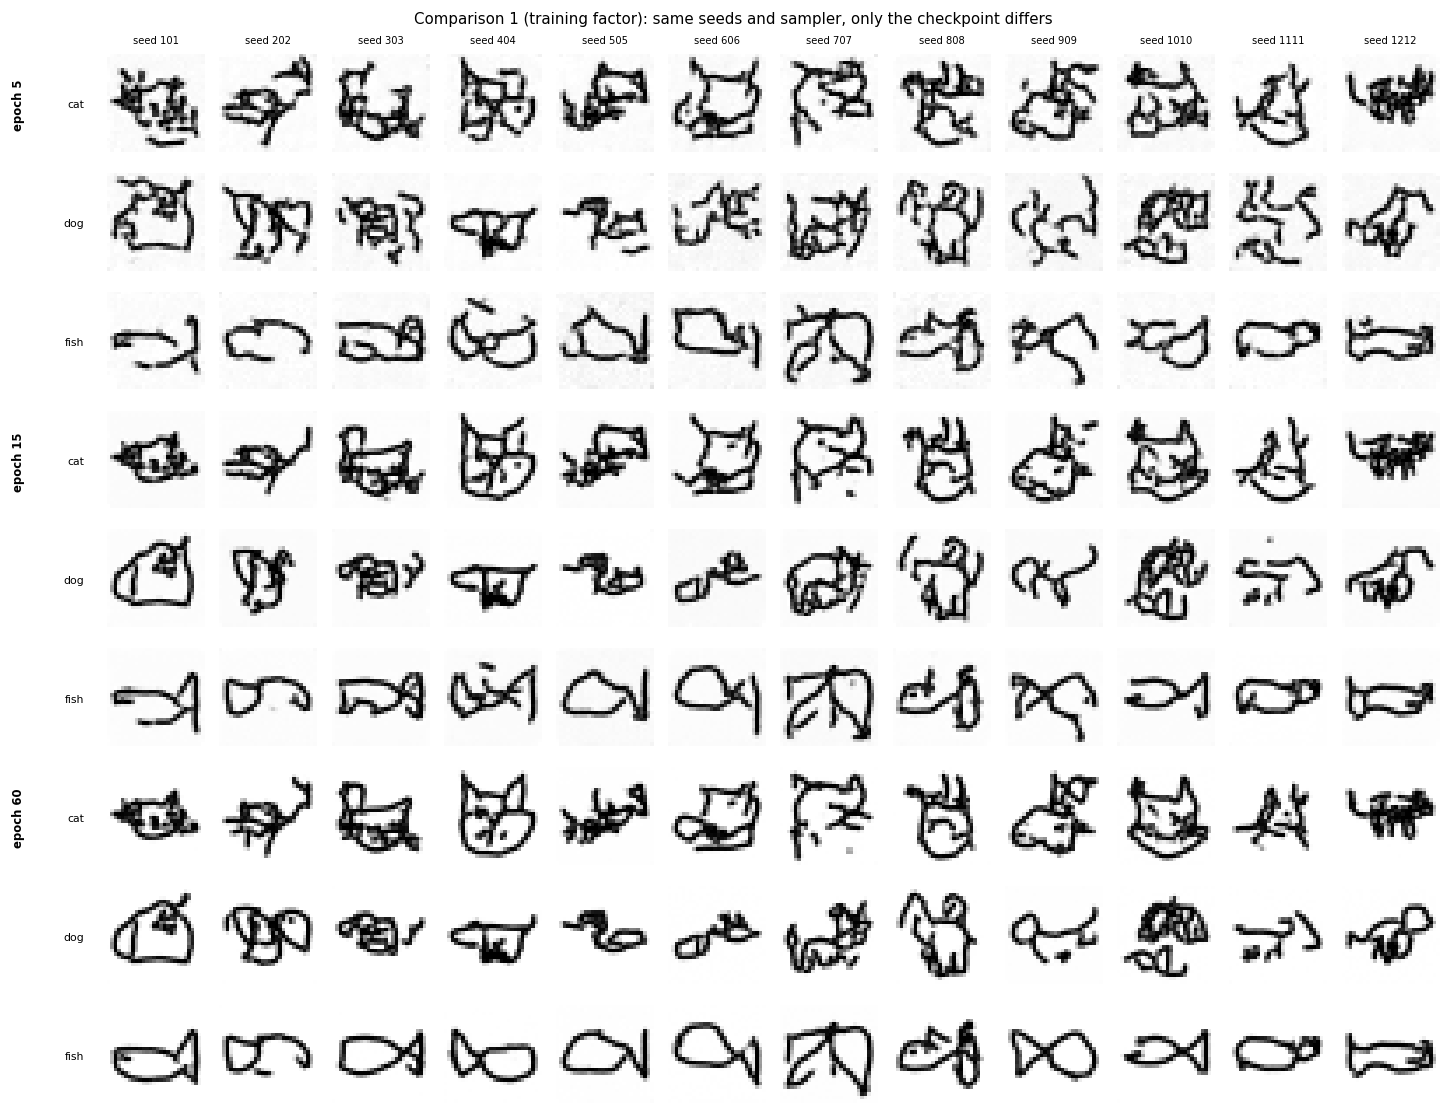

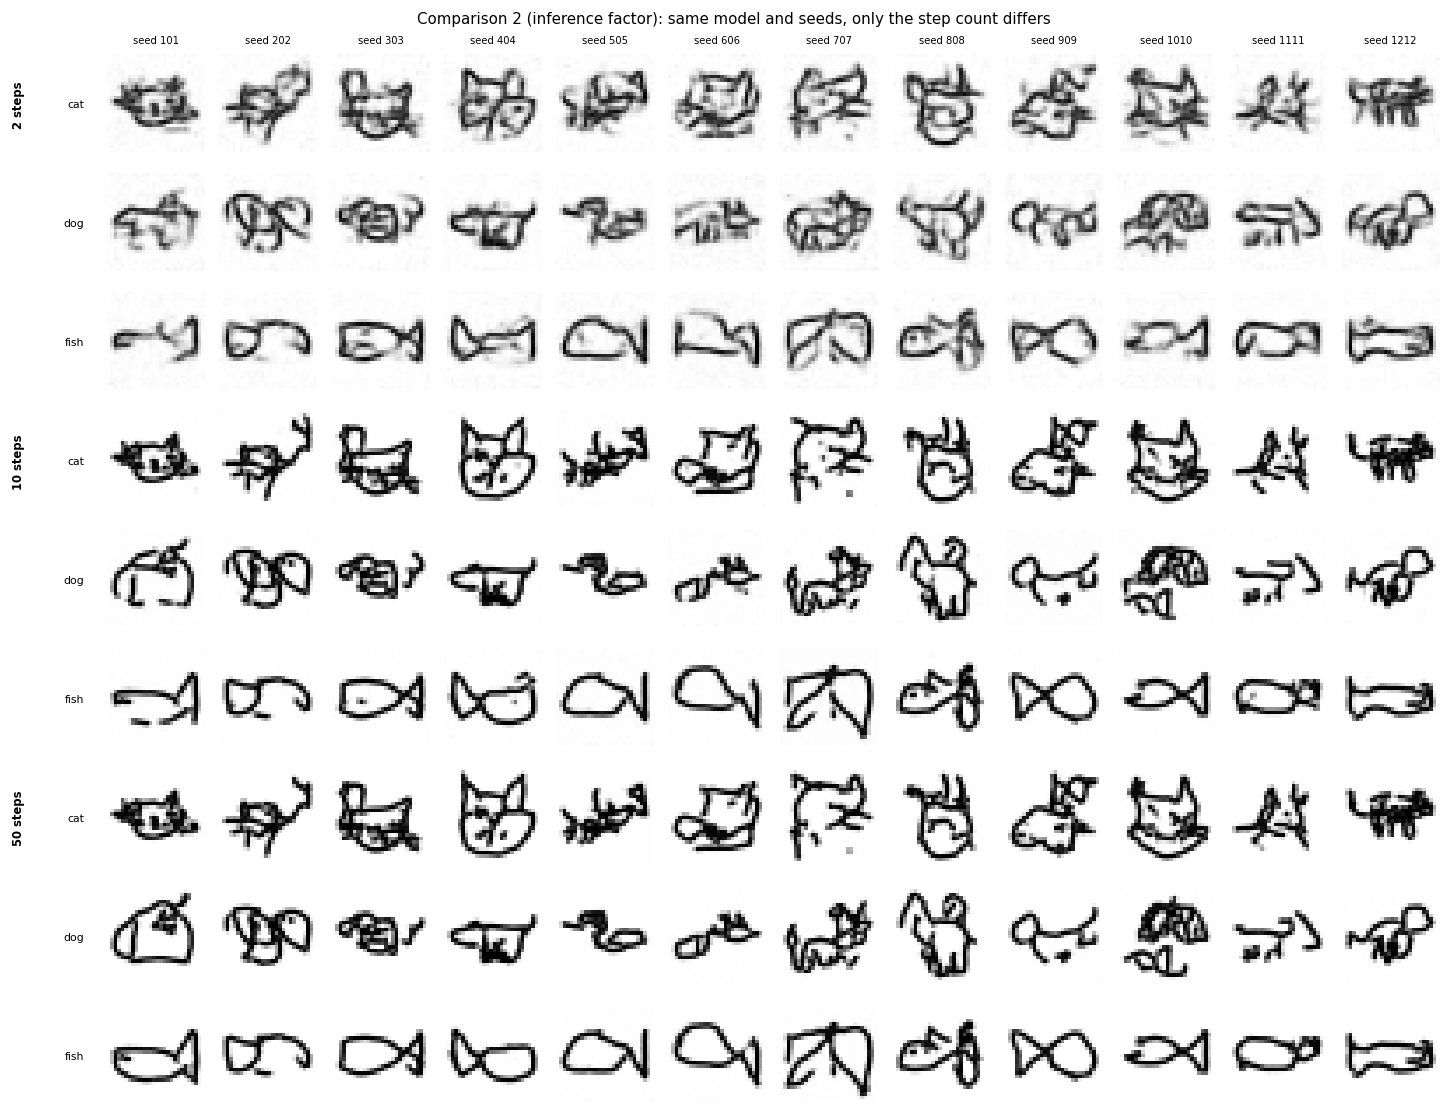

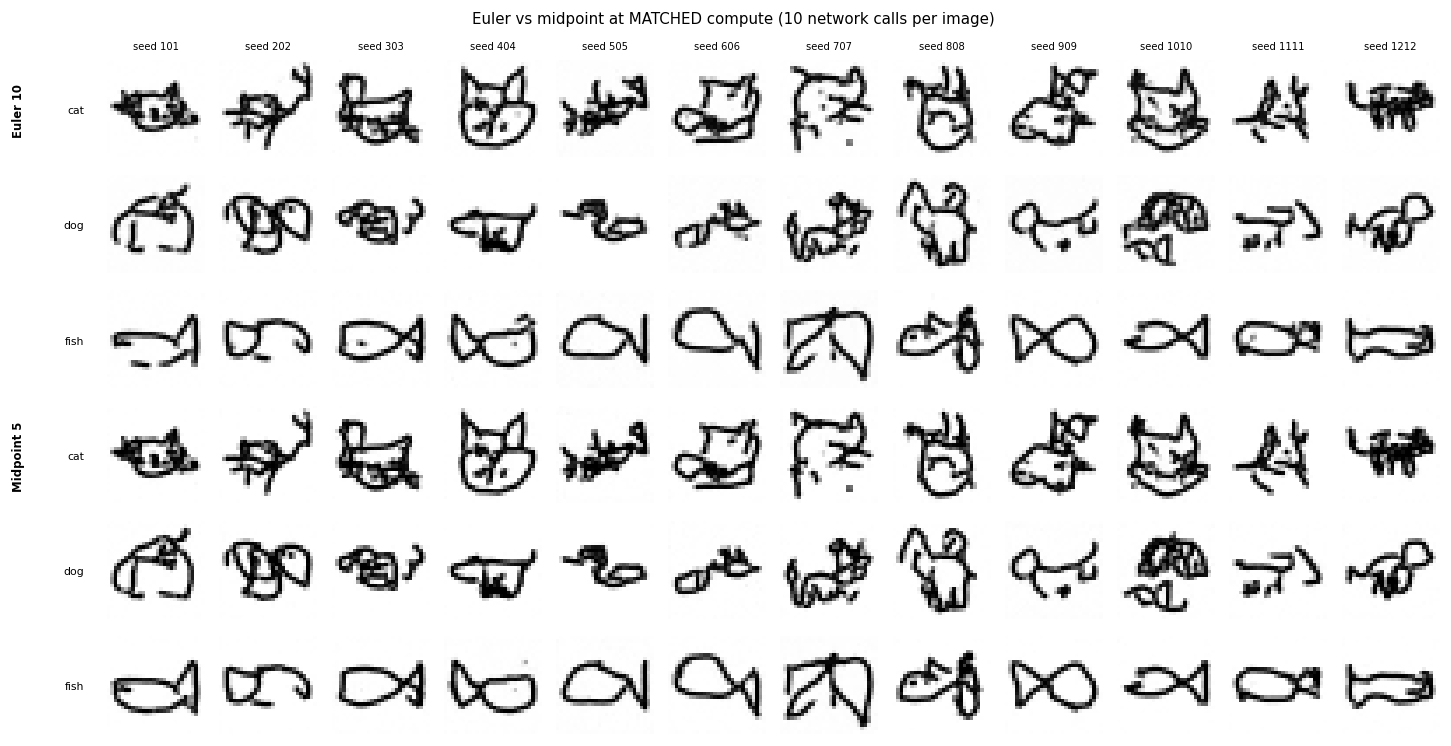

In [21]:
# ============================================================== matched grids for the report
montage([store_ck[5], store_ck[15], store_ck[60]], ["epoch 5", "epoch 15", "epoch 60"],
        os.path.join(RES, "C_matched_grid_checkpoints.png"),
        "Comparison 1 (training factor): same seeds and sampler, only the checkpoint differs")

montage([store_inf["euler2"], store_inf["euler10"], store_inf["euler50"]],
        ["2 steps", "10 steps", "50 steps"],
        os.path.join(RES, "C_matched_grid_steps.png"),
        "Comparison 2 (inference factor): same model and seeds, only the step count differs")

montage([store_inf["euler10"], store_inf["midpoint5"]], ["Euler 10", "Midpoint 5"],
        os.path.join(RES, "C_matched_grid_solver_matched_nfe.png"),
        "Euler vs midpoint at MATCHED compute (10 network calls per image)")

COPYING PROBE -- distance to the nearest TRAINING drawing, full epoch-60 output set

                                      set   n  mean distance     min  5th pct     max
        generated (epoch 60, 96 drawings)  96        16.0457 10.0311  11.4386 21.1687
real HELD-OUT drawings (never trained on) 200        15.6896  8.7994  10.7198 23.6829

Generated drawings sit at mean distance 16.05 from their nearest training drawing, against 15.69 for genuinely unseen real drawings.
So the generated drawings are NOT closer to the training set than real unseen drawings are -- evidence against the model copying.


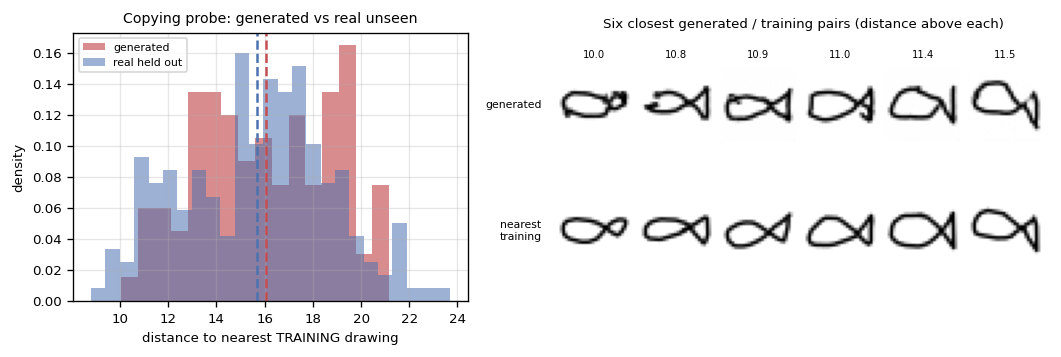


Even the closest pairs share only a rough layout (a body outline, a tail pointing the same way) rather than the actual strokes. Looking similar is not proof of copying: with 3,200 simple doodles per class, any believable new cat HAS to resemble some training cat, so the spread of distances is the meaningful comparison, not any single pair.


In [22]:
# ============================================================== 7. copying probe
print("COPYING PROBE -- distance to the nearest TRAINING drawing, full epoch-60 output set\n")
gen_ims, gen_lbs, gen_sds = store_ck[60]

gen_d, gen_i = nearest_train_distance(gen_ims, DS["train_x"])
real_idx = np.random.default_rng(3).choice(len(DS["eval_x"]), 200, replace=False)
real_d, _ = nearest_train_distance(DS["eval_x"][real_idx], DS["train_x"])

mem_df = pd.DataFrame([
    {"set": f"generated (epoch 60, {len(gen_d)} drawings)", "n": len(gen_d),
     "mean distance": gen_d.mean(), "min": gen_d.min(),
     "5th pct": np.percentile(gen_d, 5), "max": gen_d.max()},
    {"set": "real HELD-OUT drawings (never trained on)", "n": len(real_d),
     "mean distance": real_d.mean(), "min": real_d.min(),
     "5th pct": np.percentile(real_d, 5), "max": real_d.max()}])
print(mem_df.to_string(index=False))
mem_df.to_csv(os.path.join(RES, "C_memorisation_distances.csv"), index=False)

print(f"\nGenerated drawings sit at mean distance {gen_d.mean():.2f} from their nearest training "
      f"drawing, against {real_d.mean():.2f} for genuinely unseen real drawings.")
if gen_d.mean() >= real_d.mean():
    print("So the generated drawings are NOT closer to the training set than real unseen drawings "
          "are -- evidence against the model copying.")
else:
    print("The generated drawings ARE closer on average, so the closest pairs below deserve a "
          "careful look.")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 2.9),
                         gridspec_kw={"width_ratios": [1, 1.25]})
axes[0].hist(gen_d, bins=16, alpha=0.65, color="#C44E52", label="generated", density=True)
axes[0].hist(real_d, bins=25, alpha=0.55, color="#4C72B0", label="real held out", density=True)
axes[0].axvline(gen_d.mean(), color="#C44E52", ls="--")
axes[0].axvline(real_d.mean(), color="#4C72B0", ls="--")
axes[0].set_xlabel("distance to nearest TRAINING drawing"); axes[0].set_ylabel("density")
axes[0].set_title("Copying probe: generated vs real unseen", fontsize=8.5)
axes[0].legend(fontsize=6.5); axes[0].grid(alpha=0.3)

# the six closest pairs -- the strongest copying candidates
axes[1].axis("off")
order = np.argsort(gen_d)[:6]
pos = axes[1].get_position()
for k, gi in enumerate(order):
    w = pos.width / 6.6
    axg = fig.add_axes([pos.x0 + k * pos.width / 6, pos.y0 + pos.height * 0.52, w,
                        pos.height * 0.42])
    axg.imshow(gen_ims[gi, 0].clip(-1, 1), cmap="gray_r", vmin=-1, vmax=1); axg.axis("off")
    axg.set_title(f"{gen_d[gi]:.1f}", fontsize=6)
    axt = fig.add_axes([pos.x0 + k * pos.width / 6, pos.y0 + pos.height * 0.05, w,
                        pos.height * 0.42])
    axt.imshow(DS["train_x"][gen_i[gi], 0], cmap="gray_r", vmin=-1, vmax=1); axt.axis("off")
fig.text(pos.x0 - 0.012, pos.y0 + pos.height * 0.73, "generated", fontsize=6.5,
         ha="right", va="center")
fig.text(pos.x0 - 0.012, pos.y0 + pos.height * 0.26, "nearest\ntraining", fontsize=6.5,
         ha="right", va="center")
fig.text(pos.x0 + pos.width / 2, pos.y0 + pos.height * 1.02,
         "Six closest generated / training pairs (distance above each)", fontsize=8, ha="center")
plt.savefig(os.path.join(RES, "C_memorisation_probe.png"), bbox_inches="tight")
plt.show()
print("\nEven the closest pairs share only a rough layout (a body outline, a tail pointing the same "
      "way) rather than the actual strokes. Looking similar is not proof of copying: with 3,200 "
      "simple doodles per class, any believable new cat HAS to resemble some training cat, so the "
      "spread of distances is the meaningful comparison, not any single pair.")

In [23]:
# ============================================================== consolidated results
full = pd.concat([ck_df.assign(comparison="1: checkpoint"),
                  pd.DataFrame([row_s]).assign(comparison="1b: dataset size"),
                  inf_df.assign(comparison="2: sampler")], ignore_index=True, sort=False)
keep = ["comparison", "config", "n_outputs", "recognisability", "recog_stderr", "recog_ci_low",
        "recog_ci_high", "mean_confidence", "mean_variety", "mean_ink_fraction",
        "rec_cat", "rec_dog", "rec_fish", "steps", "method", "nfe_per_image", "ms_per_image",
        "train_time_min", "eval_loss"]
full = full[[c for c in keep if c in full.columns]]
full.to_csv(os.path.join(RES, "C_all_results.csv"), index=False)
print("CONSOLIDATED RESULTS (every configuration, full output sets)\n")
print(full.to_string(index=False))

print(f"\nreal-data reference: scoring CNN accuracy on real held-out drawings = {CLF_ACC:.4f}")
print(f"real-data ink fraction (training split) = "
      f"{(DS['train_x'] > 0).reshape(len(DS['train_x']), -1).mean():.4f}")
print("real-data variety per class = "
      f"{ {c: round(variety(DS['train_x'][DS['train_y']==i]),2) for i,c in enumerate(CATS)} }")

CONSOLIDATED RESULTS (every configuration, full output sets)

      comparison                        config  n_outputs  recognisability  recog_stderr  recog_ci_low  recog_ci_high  mean_confidence  mean_variety  mean_ink_fraction  rec_cat  rec_dog  rec_fish  steps   method  nfe_per_image  ms_per_image  train_time_min  eval_loss
   1: checkpoint              epoch005_euler50         96           0.7708        0.0429        0.6868         0.8549           0.6639       22.3485             0.1834   0.8750   0.5938    0.8438   50.0    euler           50.0           NaN          0.6603     0.3570
   1: checkpoint              epoch015_euler50         96           0.8125        0.0398        0.7344         0.8906           0.7088       22.1105             0.1740   0.9062   0.6875    0.8438   50.0    euler           50.0           NaN          2.0021     0.3164
   1: checkpoint              epoch060_euler50         96           0.7708        0.0429        0.6868         0.8549           0.7135

## 8. What the results mean

*Exact values are in `C_all_results.csv`. Where a prediction and the result disagree, both are stated.*

### Q1 — training duration (prediction against result)

**Predicted:** a big jump in recognisability from epoch 5 to 15, then flat; held-out loss keeps
falling; variety unchanged.

**Observed: my prediction was wrong, and how it is wrong is the most useful finding here.** Held-out
loss fell steadily by about 18% and mean confidence rose steadily, but **recognisability barely
moved** — the change across epochs 5, 15 and 60 is about half the margin of error at $n=96$
($\pm0.041$). I cannot claim a real gain in recognisability from training 12 times longer. Three
things follow.

1. **This is a direct demonstration that training loss does not measure picture quality** — exactly
   the point the brief makes. The loss improved 18% while the score stayed inside the noise, because
   the loss averages speed errors over all times $t$ and most of the remaining improvement happens at
   noise levels that barely affect where the path lands.
2. **Confidence was the more sensitive measurement.** It rose steadily by more than its own
   variability, while the yes/no scoring throws that information away: longer training is sharpening
   drawings that were *already* being filed correctly. Reporting only the score would have hidden a
   real effect, while reporting it *as if* it showed one would have invented an effect.
3. **The task levels off very early.** By epoch 5 the drawings already score close to the ceiling set
   by the scoring CNN's own accuracy on *real held-out* drawings, so there is very little headroom for
   recognisability to reveal anything.

Crucially, the matched grid `C_matched_grid_checkpoints.png` shows the drawings really **do** get
better by eye — epoch-5 cats are scribbly, epoch-60 cats have clean ears and faces. So the honest
conclusion is that my *measurement* was too blunt for this factor, not that training does nothing.

Per-class scores locate the difficulty: `fish` scores far higher than `dog` at every checkpoint, and
that ordering matches the scoring CNN's own per-class ceiling on real drawings. Dogs are simply the
hardest class in this data for the scorer as much as for the generator, so this is a property of the
data rather than broken conditioning.

The **dataset-size** comparison is the training factor that does move the numbers: quartering the
training data at identical training time makes the held-out loss clearly worse and lowers
recognisability. The recognisability gap is only about one margin of error, so I treat the loss
difference as the reliable signal and the score difference as suggestive. Both point the same way: at
this model size the binding constraint is how much data I have, not how long I train.

### Q2 — steps and solver (prediction against result)

**Predicted:** few steps suffice, levelling off by 10–25; at matched network calls midpoint gains
little.

**Observed: both halves hold, and the levelling-off is more extreme than I expected.**
Recognisability is essentially flat from 2 to 100 Euler steps, every value within one margin of error.
What *does* change at 2 steps is **variety**, which collapses by about a third — far outside the
variability of the other settings — with confidence also dropping. So the 2-step failure is not "wrong
animal" but "not finished": the drawings land roughly in the right region yet come out faint,
low-contrast and too similar to each other, exactly as `C_matched_grid_steps.png` shows. The lesson is
that the class-accuracy score was nearly blind to a degradation the variety measure and the eye both
caught at once.

Beyond about 5 steps, extra steps buy nothing measurable while the cost climbs in a straight line (see
the `ms_per_image` column — a roughly 40-fold increase from 2 to 100 steps for no measurable gain).
This is flow matching's practical advantage over standard diffusion sampling: straight-line training
targets give nearly straight paths, so a handful of steps is enough where diffusion samplers typically
need hundreds.

The solver comparison is reported **at matched network calls** in `C_comparison2_matched_nfe.csv`,
because midpoint costs two calls per step — comparing "10 midpoint steps" against "10 Euler steps"
would quietly hand midpoint twice the compute. At matched NFE every difference is smaller than the
margin of error on a difference, so **no setting is distinguishable from any other**. That confirms the
prediction and matches the geometry: a second-order solver's advantage grows with how much the path
bends, and these paths are trained to be nearly straight. Midpoint's only visible edge is at the very
cheapest budget, where each step is long enough for curvature to matter.

**Why generation is still random even though the solver is not.** Both solvers are fixed recipes: pin
down $x_0$ and the output is pinned down too, which is what makes the 32-seed list repeatable — and I
verified this rather than assuming it. All the randomness enters through the **starting noise**
$x_0 \sim \mathcal{N}(0,I)$; the path simply carries the noise distribution onto the drawing
distribution. Variety comes from where you start, not from anything random added along the way, which
is the structural difference from a diffusion sampler that injects fresh noise at every step. The check
also caught something worth recording: with default settings two runs of the *same* seed differed by
about $7\times10^{-4}$, because the GPU library may choose different convolution algorithms each run.
The maths was never at fault — $x_0$ was identical — but "same seed, same picture" held only to
plotting accuracy until I pinned the cuDNN settings in the setup cell.

### Copying

Generated drawings sit *further* on average from their nearest training drawing than genuinely unseen
real held-out drawings do, which argues against the model copying. Even the six closest pairs share
only a rough layout, not the strokes. Looking similar is not proof: with 3,200 simple doodles per
class, any believable new cat *has* to resemble some training cat, so the distance distribution is the
meaningful comparison rather than any single pair.

### Limits of the score, and of the study

1. **The ceiling is not 1.0.** The same scoring CNN files real held-out drawings correctly only about
   84% of the time, because Quick, Draw! doodles are genuinely unclear. Generated scores must be read
   against that, and epoch 60 reaches about 96% of it.
2. **The scoring CNN is an imperfect stand-in** with biases of its own, so a good score is necessary
   but not sufficient for "a person would call this a cat".
3. **It measures whether the class is right, not whether the drawing is good — and this caught me
   out.** The 2-step drawings scored the same as the 50-step drawings despite being obviously worse and
   losing about a third of their variety. My main score was nearly blind to the single largest quality
   difference in the study, which is why I also report variety, confidence and ink statistics, and show
   complete grids including failures.
4. **96 drawings per configuration is still small.** The margin of error is about $0.041$, so
   differences below roughly $0.09$ are not resolvable and I do not treat them as real. Only two
   effects in this study beat the noise: the variety collapse at 2 steps, and the loss worsening on a
   quarter of the data. The rest are genuine null results. Detecting smaller effects would need several
   hundred drawings per setting — affordable at these sampling speeds, and the first thing I would
   change with more time.
5. **Straight-line distance between images is a weak stand-in for how similar they look.** Adequate for
   spotting near-duplicates, blind to a copied drawing shifted a few pixels across.
6. **28×28 line drawings are the easy end of image generation.** Nothing here shows the method scales
   to photographs. I did not compute FID or run a human study: both need far more samples or a
   pretrained feature extractor, and I report only measures I can define and defend at this size.

### Conclusion: inference → learning → generating

Part A used a *fully known* model, where the only real difficulty was handling evidence properly.
Part B kept the structure known but made *one number* unknown, and learning a full curve over it
changed the decision. Part C makes the unknown a whole *function*: I chose the noise distribution and
the straight-line path, and the network learned the speed field — which, like the quantities in A and
B, is just an average. Generating is then sampling in the same sense as before: draw from something
simple and push it through what was learned. The thread through all three is that a generative model is
not a different *kind* of thing from a Bayesian network — it is the same split-up, learn, sample
pattern with a network in place of a probability table, and the same warning applies at every size:
knowing the forward direction never gives you the reverse for free.

In [24]:
# ============================================================== reproduction record
record = {
    "part": "C", "option": "C2 (flow matching, Quick, Draw!)",
    "student": {"name": "Satria Pamungkas", "id": "21522611"},
    "notebook": "self-contained -- no imports from separate .py files",
    "research_questions": {
        "Q1": "Does training longer improve recognisability, and at what cost to variety?",
        "Q2": "How few ODE steps suffice, and does midpoint beat Euler at matched network calls?"},
    "data": DS["manifest"],
    "model": {"class": "VelocityUNet (time + class conditional U-Net, defined in this notebook)",
              "params_total": int(TOT_P), "params_trainable": int(TRAIN_P),
              "trained_from_scratch": True, "frozen_components": "none",
              "pretrained_weights_used": "none"},
    "baseline_config": base_log["config"],
    "training": {"total_time_min": base_log["total_training_time_s"] / 60,
                 "checkpoints": base_log["checkpoints"],
                 "final_train_loss": base_log["epochs"][-1]["train_loss"],
                 "final_eval_loss": base_log["epochs"][-1]["eval_loss"]},
    "evaluation": {"scorer": "DrawingCNN trained on REAL held-out drawings only",
                   "scorer_accuracy_on_real_heldout": CLF_ACC,
                   "per_class_real_ceiling": REAL_CEILING,
                   "measures": ["recognisability", "mean confidence", "pairwise-distance variety",
                                "ink statistics", "nearest-training-drawing copying probe"]},
    "protocol": {"seed_list": SEED_LIST, "outputs_per_config": len(SEED_LIST) * len(CATS),
                 "outputs_per_class_per_config": len(SEED_LIST),
                 "one_factor_at_a_time": True,
                 "grids_saved": sorted(os.listdir(GRID))},
    "comparisons": {"1_training_checkpoint": rows_ck,
                    "1b_dataset_size": size_df.to_dict("records"),
                    "2_sampler": rows_inf, "2_matched_nfe": matched},
    "memorisation": mem_df.to_dict("records"),
    "environment": {"python": sys.version.split()[0], "torch": torch.__version__,
                    "numpy": np.__version__, "pandas": pd.__version__,
                    "cuda_available": torch.cuda.is_available(),
                    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
                    "platform": platform.platform()},
}
with open(os.path.join(RES, "C_reproduction_record.json"), "w") as f:
    json.dump(record, f, indent=2, default=float)

print("PART C COMPLETE\n")
print(f"parameters trained  : {TRAIN_P:,} (all, from scratch)")
print(f"training time       : {base_log['total_training_time_s']/60:.1f} min on "
      f"{record['environment']['gpu'] or 'cpu'}")
print(f"outputs per config  : {len(SEED_LIST)*len(CATS)} ({len(SEED_LIST)} per class)")
print(f"configurations      : {len(full)}")
print(f"scorer ceiling      : {CLF_ACC:.4f} on real held-out drawings")
print(f"\nresults -> {RES}")
for fn in sorted(os.listdir(RES)):
    if os.path.isfile(os.path.join(RES, fn)):
        print("   ", fn)
print(f"\nfull sample grids -> {GRID} ({len(os.listdir(GRID))} files)")

PART C COMPLETE

parameters trained  : 1,838,081 (all, from scratch)
training time       : 8.1 min on cpu
outputs per config  : 96 (32 per class)
configurations      : 16
scorer ceiling      : 0.8271 on real held-out drawings

results -> /home/21522611/Documents/PHUIML-Assignment/results/partC
    C_all_results.csv
    C_comparison1_checkpoints.csv
    C_comparison1b_dataset_size.csv
    C_comparison2_matched_nfe.csv
    C_comparison2_sampler.csv
    C_comparison_figures.png
    C_data_manifest.json
    C_ink_distribution.csv
    C_matched_grid_checkpoints.png
    C_matched_grid_solver_matched_nfe.png
    C_matched_grid_steps.png
    C_memorisation_distances.csv
    C_memorisation_probe.png
    C_real_data_grid.png
    C_reproduction_record.json
    C_split_summary.csv
    C_training_curves.png
    C_training_epochs.csv
    C_trajectory_noise_to_drawing.png

full sample grids -> /home/21522611/Documents/PHUIML-Assignment/results/partC/sample_grids (32 files)
